# WattIf — Section 3 en R

Réplication en R de la section 3 du groupe : stationnarité, ARIMA/SARIMA, puis (partie 2) VAR, Johansen/VECM et GARCH avec les spécifications exactes du notebook 05, et (partie 3) l'extension de la section 7 : corrélation glissante température-consommation.
Objectif : vérifier que R et Python donnent les mêmes conclusions sur les mêmes données et le même protocole.

**Protocole repris à l'identique de Python** : `data/daily.csv`, split chronologique 90/10
(3 506 jours d'apprentissage jusqu'au 06/08/2025, 390 jours de test), validation interne sur les
56 derniers jours du train, horizon h = 7, seed 42, chemins relatifs.

À ouvrir depuis la racine du projet, avec le noyau **R**. Packages nécessaires (une seule fois, dans la console R) :
```r
options(repos = "https://cloud.r-project.org", timeout = 600)
install.packages(c("forecast", "tseries", "urca", "uroot", "tsibble", "vars", "rugarch", "zoo", "sandwich", "IRdisplay"))
```
Durée d'exécution complète : environ une minute.

In [1]:
# packages, versions, reproductibilité
# Packages de la section 3 en R ; chacun correspond à un package Python utilisé par le groupe
suppressPackageStartupMessages({
  library(forecast)   # ARIMA/SARIMA, auto.arima, ndiffs/nsdiffs (≈ statsmodels + pmdarima)
  library(tseries)    # tests KPSS et Jarque-Bera
  library(urca)       # test ADF avec choix des retards par AIC (≈ adfuller)
})
has_tsibble <- requireNamespace("tsibble", quietly = TRUE)

set.seed(42)                                  # règle commune : seed 42
cat(R.version.string, "\n")
for (p in c("forecast", "tseries", "urca", "tsibble"))
  if (requireNamespace(p, quietly = TRUE)) cat(p, as.character(packageVersion(p)), "\n")

dir.create("figures/R", recursive = TRUE, showWarnings = FALSE)   # figures de la partie R
dir.create("forecasts", showWarnings = FALSE)                     # format commun du groupe
dir.create("exports/R", recursive = TRUE, showWarnings = FALSE)   # tableaux de la partie R

Warning message:
"package 'forecast' was built under R version 4.5.3"
Warning message:
"package 'tseries' was built under R version 4.5.3"
Warning message:
"package 'urca' was built under R version 4.5.3"


R version 4.5.2 (2025-10-31 ucrt) 
forecast 9.0.2 
tseries 0.10.63 
urca 1.3.4 
tsibble 1.2.0 


## 1. Chargement et contrôle des données

In [2]:
# chargement et contrôle des données
# Même fichier que Python : data/daily.csv préparé par le notebook 01 (chemin relatif)
df <- read.csv("data/daily.csv", stringsAsFactors = FALSE)
df$date <- as.Date(df$date)
df <- df[order(df$date), ]

# Contrôles identiques à ceux de la section 3.1 : un jour par ligne, sans trou ni valeur manquante
stopifnot(!anyDuplicated(df$date),
          all(diff(df$date) == 1),
          !anyNA(df$conso_gwh))
cat(nrow(df), "jours :", format(min(df$date)), "→", format(max(df$date)), "\n")

3896 jours : 2016-01-01 → 2026-08-31 


### Format `tsibble`
Un `tsibble` est un tableau dont l'index est la date : il garantit qu'il y a exactement une observation par jour. Les modèles du package `forecast` utilisent ensuite des objets `ts` classiques.

In [3]:
# format tsibble (série temporelle « tidy »)
# tsibble = tableau dont l'index est la date ; vérifie la régularité journalière
if (has_tsibble) {
  library(tsibble)
  conso_tsb <- as_tsibble(df, index = date)
  print(conso_tsb[, c("date", "conso_gwh", "temp_moy", "hdd")])
  cat("Trous dans l'index :", has_gaps(conso_tsb)$.gaps, "\n")   # FALSE attendu
}

Warning message:
"package 'tsibble' was built under R version 4.5.3"

Attaching package: 'tsibble'


The following objects are masked from 'package:base':

    intersect, setdiff, union




# A tsibble: 3,896 x 4 [1D]
   date       conso_gwh temp_moy   hdd
   <date>         <dbl>    <dbl> <dbl>
 1 2016-01-01     1291.     7.26 10.7 
 2 2016-01-02     1332.     8.90  9.10
 3 2016-01-03     1363.     7.40 10.6 
 4 2016-01-04     1546.     8.31  9.69
 5 2016-01-05     1616.     7.70 10.3 
 6 2016-01-06     1633.     7.58 10.4 
 7 2016-01-07     1626.     8.72  9.28
 8 2016-01-08     1604.     7.60 10.4 
 9 2016-01-09     1427.     8.88  9.12
10 2016-01-10     1392.     8.32  9.68
# ℹ 3,886 more rows
Trous dans l'index : FALSE 


## 2. Découpage apprentissage / test
`int(0.9 * n)` en Python correspond à `floor(0.9 * n)` en R : on obtient exactement les mêmes dates que les notebooks Python.

In [4]:
# split chronologique 90/10 identique au groupe
# int(0.9 * n) en Python = floor(0.9 * n) en R → 3506 jours d'apprentissage
n_train <- floor(0.9 * nrow(df))
train_df <- df[1:n_train, ]
test_df  <- df[(n_train + 1):nrow(df), ]

# Validation interne de la section 3.1 : les 56 derniers jours du train (8 blocs de 7 jours)
VALIDATION_DAYS <- 56; H <- 7
est_df <- train_df[1:(n_train - VALIDATION_DAYS), ]
val_df <- train_df[(n_train - VALIDATION_DAYS + 1):n_train, ]

# Objets ts de fréquence 7 (saisonnalité hebdomadaire) pour le package forecast
to_ts <- function(x) ts(x, frequency = 7)
y_train <- to_ts(train_df$conso_gwh)
y_est   <- to_ts(est_df$conso_gwh)

periode <- function(nom, d) cat(sprintf("%-12s %4d jours  %s → %s\n", nom, nrow(d),
                                       format(min(d$date)), format(max(d$date))))
periode("Estimation", est_df); periode("Validation", val_df)
periode("Train", train_df);    periode("Test", test_df)

Estimation   3450 jours  2016-01-01 → 2025-06-11
Validation     56 jours  2025-06-12 → 2025-08-06
Train        3506 jours  2016-01-01 → 2025-08-06
Test          390 jours  2025-08-07 → 2026-08-31


## 3. Stationnarité : ADF et KPSS

- **ADF** : H0 = racine unitaire (non stationnaire). `urca::ur.df` avec constante et retards choisis par AIC, comme `adfuller(autolag="AIC")`.
- **KPSS** : H0 = stationnaire. `tseries::kpss.test` ne choisit pas les retards comme statsmodels (0,496 au lieu de 0,403 sur la série brute). On recode donc la règle automatique de Hobijn et al. (1998), celle de `kpss(nlags="auto")`, pour une comparaison exacte.

In [5]:
# tests ADF et KPSS sur le train (brut, Δ1, Δ1Δ7)
# ADF : H0 = racine unitaire ; KPSS : H0 = stationnaire. Même règle de décision que le notebook 02.
y <- train_df$conso_gwh
series <- list("Série brute" = y,
               "Δ1"          = diff(y, 1),
               "Δ1Δ7"        = diff(diff(y, 1), 7))

adf_test <- function(s, maxlag = ceiling(12 * (length(s) / 100)^(1/4))) {
  # Même procédure que statsmodels adfuller(regression="c", autolag="AIC") :
  # 1) nombre de retards choisi par AIC sur un échantillon commun ; 2) régression refaite avec ce nombre
  #    de retards sur tout l'échantillon disponible
  dy <- diff(s); n <- length(dy)
  reg <- function(k, debut) {
    i <- debut:n
    X <- cbind(s[i], if (k > 0) sapply(1:k, function(j) dy[i - j]))   # niveau retardé + différences retardées
    lm(dy[i] ~ X)
  }
  aic <- sapply(0:maxlag, function(k) AIC(reg(k, maxlag + 1)))
  k <- which.min(aic) - 1
  stat <- coef(summary(reg(k, k + 1)))[2, "t value"]
  cv <- c(-3.43, -2.86, -2.57)                       # valeurs critiques de MacKinnon (constante, grand n)
  p  <- if (stat < cv[1]) "< 0.01" else if (stat < cv[2]) "0.01–0.05" else
        if (stat < cv[3]) "0.05–0.10" else "> 0.10"
  c(stat = round(stat, 3), p = p, retards = k)
}
kpss_test <- function(x) {
  # KPSS avec constante et nombre de retards automatique de Hobijn et al. (1998),
  # la même règle que statsmodels kpss(nlags="auto") : résultats comparables à Python
  n <- length(x); e <- x - mean(x)
  covlags <- floor(n^(2/9)); s0 <- sum(e^2) / n; s1 <- 0
  for (i in seq_len(covlags)) {
    g <- sum(e[(i + 1):n] * e[1:(n - i)]) / (n / 2)
    s0 <- s0 + g; s1 <- s1 + i * g
  }
  lags <- floor(1.1447 * ((s1 / s0)^2)^(1/3) * n^(1/3))
  # variance de long terme (noyau de Bartlett) et statistique KPSS
  lrv <- sum(e^2) / n
  for (i in seq_len(lags)) lrv <- lrv + 2 * (1 - i / (lags + 1)) * sum(e[(i + 1):n] * e[1:(n - i)]) / n
  stat <- sum(cumsum(e)^2) / (n^2 * lrv)
  # p-value interpolée dans la table de Kwiatkowski et al., bornée à [0,01 ; 0,10]
  p <- approx(c(0.347, 0.463, 0.574, 0.739), c(0.10, 0.05, 0.025, 0.01), stat, rule = 2)$y
  c(stat = stat, p = p, lags = lags)
}
tests <- do.call(rbind, lapply(names(series), function(nm) {
  s <- series[[nm]]
  a <- adf_test(s)
  k <- kpss_test(s)
  data.frame(Serie = nm, ADF_stat = a[["stat"]], ADF_p = a[["p"]],
             KPSS_stat = round(k[["stat"]], 3), KPSS_p = round(k[["p"]], 4),
             KPSS_retards = k[["lags"]],
             Conclusion = ifelse(a[["p"]] %in% c("< 0.01", "0.01–0.05") & k[["p"]] > 0.05,
                                 "stationnaire", "non stationnaire"))
}))
print(tests, row.names = FALSE)
write.csv(tests, "exports/R/tests_stationnarite_R.csv", row.names = FALSE)

# Recommandations automatiques (équivalents de pmdarima ndiffs / nsdiffs)
cat("d (KPSS) :", ndiffs(y_train, test = "kpss"),
    "| d (ADF) :", ndiffs(y_train, test = "adf"),
    "| D (OCSB) :", nsdiffs(y_train, test = "ocsb"),
    "| D (CH) :", tryCatch(nsdiffs(y_train, test = "ch"),          # forecast ≥ 9 : nécessite uroot
                           error = function(e) "package uroot absent"), "\n")

       Serie ADF_stat  ADF_p KPSS_stat KPSS_p KPSS_retards   Conclusion
 Série brute   -4.101 < 0.01     0.403 0.0759           37 stationnaire
          Δ1  -12.207 < 0.01     0.016 0.1000           84 stationnaire
        Δ1Δ7  -18.398 < 0.01     0.007 0.1000           16 stationnaire
d (KPSS) : 1 | d (ADF) : 0 | D (OCSB) : 0 | D (CH) : 1 


### Lecture
Résultats identiques à Python au millième : ADF −4,101 / −12,207 / −18,398 ; KPSS 0,403 (p = 0,076), 0,016 et 0,007.
Les recommandations automatiques divergent comme en Python (`ndiffs` : d = 1 selon KPSS, 0 selon ADF ; `nsdiffs` : D = 0 selon OCSB, 1 selon Canova-Hansen).
R confirme donc le choix du groupe : **d = 1, D = 1, s = 7**.

## 4. Autocorrélations

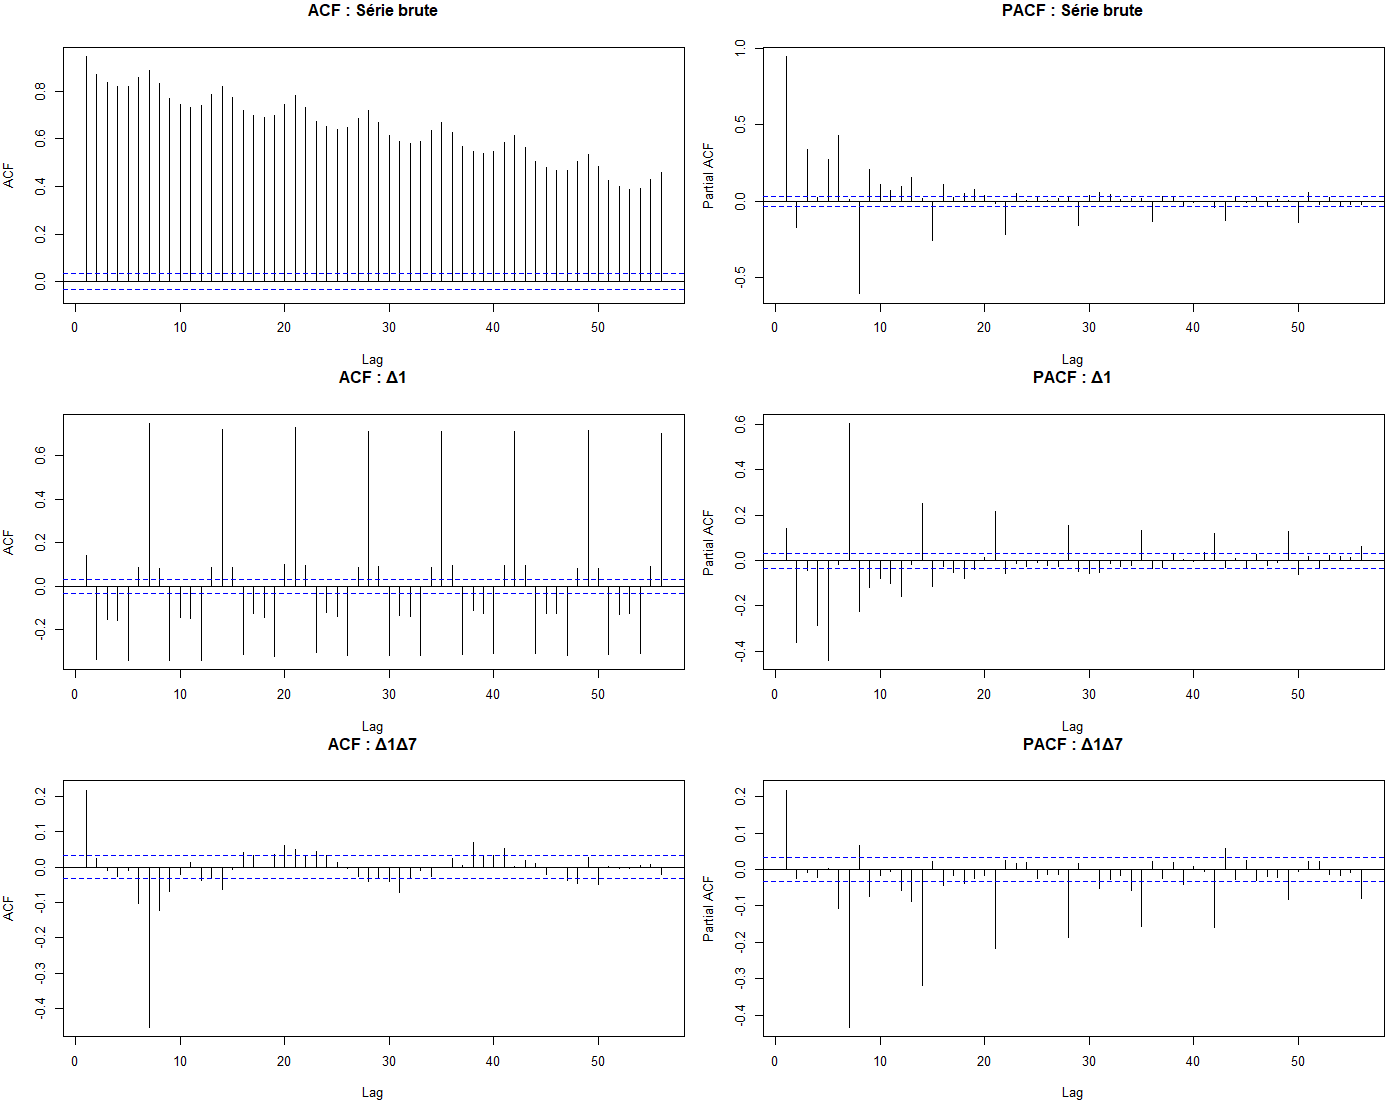

In [6]:
# ACF / PACF (brute, Δ1, Δ1Δ7)
# Même lecture que le notebook 02 : pics tous les 7 jours, puis MA saisonnier après Δ1Δ7
png("figures/R/acf_pacf_R.png", width = 1400, height = 1100, res = 120)
par(mfrow = c(3, 2), mar = c(4, 4, 3, 1))
for (nm in names(series)) {
  Acf(series[[nm]],  lag.max = 56, main = paste("ACF :", nm))
  Pacf(series[[nm]], lag.max = 56, main = paste("PACF :", nm))
}
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/acf_pacf_R.png")

## 5. SARIMA : candidats et `auto.arima`

Mêmes candidats qu'en section 3.1 (onze ordres, dont les quatre ajoutés après les premiers diagnostics), estimés par maximum de vraisemblance exact sur l'échantillon d'estimation (3 450 jours).
Constante incluse uniquement sans différenciation, comme `trend='c'` dans `SARIMAX`.

In [7]:
# candidats SARIMA (mêmes ordres qu'en section 3.1) ajustés sur l'estimation
# Hypothèses issues des ACF/PACF ; d=1, D=1, s=7 retenus en section 2, variantes D=0 incluses
specs <- list(
  ARIMA_110      = list(c(1,1,0), c(0,0,0)),
  ARIMA_011      = list(c(0,1,1), c(0,0,0)),
  SARIMA_011_011 = list(c(0,1,1), c(0,1,1)),
  SARIMA_110_011 = list(c(1,1,0), c(0,1,1)),
  SARIMA_111_011 = list(c(1,1,1), c(0,1,1)),
  SARIMA_110_101 = list(c(1,1,0), c(1,0,1)),
  SARIMA_100_101 = list(c(1,0,0), c(1,0,1)),
  SARIMA_211_011 = list(c(2,1,1), c(0,1,1)),
  SARIMA_212_011 = list(c(2,1,2), c(0,1,1)),
  SARIMA_311_011 = list(c(3,1,1), c(0,1,1)),
  SARIMA_110_111 = list(c(1,1,0), c(1,1,1))
)
fit_spec <- function(yts, sp) {
  d_tot <- sp[[1]][2] + sp[[2]][2]
  # constante seulement sans différenciation (comme trend='c' en section 3.1), estimation ML exacte
  Arima(yts, order = sp[[1]], seasonal = list(order = sp[[2]], period = 7),
        include.mean = (d_tot == 0), method = "ML")
}
fits <- lapply(specs, fit_spec, yts = y_est)

# auto.arima : même espace de recherche que auto_arima de la section 3.1 (p,q ≤ 2 ; P,Q ≤ 1 ; AIC)
fits$auto_SARIMA <- auto.arima(y_est, max.p = 2, max.q = 2, max.P = 1, max.Q = 1,
                               ic = "aic", stepwise = TRUE, seasonal = TRUE)
fits$auto_ARIMA  <- auto.arima(y_est, max.p = 2, max.q = 2, ic = "aic",
                               stepwise = TRUE, seasonal = FALSE)
cat("auto_SARIMA :", arimaorder(fits$auto_SARIMA), "\n")
cat("auto_ARIMA  :", arimaorder(fits$auto_ARIMA), "\n")

auto_SARIMA : 1 0 1 1 1 0 7 
auto_ARIMA  : 2 1 2 


## 6. Validation interne glissante

Huit blocs de sept jours. À chaque origine, `Arima(historique, model = fit)` réapplique le modèle **sans réestimer ses paramètres**, c'est l'équivalent R de `results.append(..., refit=False)` en Python.

In [8]:
# validation interne glissante (8 blocs de 7 jours, paramètres figés)
# À chaque origine : les paramètres restent fixes, seules les observations passées sont ajoutées
rolling_forecast <- function(fit, y_hist, y_new, h = 7, level = 95) {
  out <- NULL
  for (start in seq(1, length(y_new), by = h)) {
    idx  <- start:min(start + h - 1, length(y_new))
    hist <- c(y_hist, y_new[seq_len(start - 1)])
    upd  <- Arima(to_ts(hist), model = fit)          # réapplique le modèle sans réestimer
    fc   <- forecast(upd, h = length(idx), level = level)
    out  <- rbind(out, data.frame(i = idx, horizon = seq_along(idx),
                                  prevision = as.numeric(fc$mean),
                                  borne_inferieure_95 = as.numeric(fc$lower),
                                  borne_superieure_95 = as.numeric(fc$upper)))
  }
  out
}
naive_forecast <- function(y_hist, y_new, h = 7, seasonal = TRUE) {
  p <- numeric(0)
  for (start in seq(1, length(y_new), by = h)) {
    hist <- c(y_hist, y_new[seq_len(start - 1)])
    n <- min(h, length(y_new) - start + 1)
    p <- c(p, if (seasonal) rep(tail(hist, 7), length.out = n) else rep(tail(hist, 1), n))
  }
  p
}
scores <- function(obs, prev) c(MAE = mean(abs(obs - prev)), RMSE = sqrt(mean((obs - prev)^2)))

val_rows <- lapply(names(fits), function(nm) {
  p <- rolling_forecast(fits[[nm]], est_df$conso_gwh, val_df$conso_gwh)$prevision
  data.frame(modele = nm, t(scores(val_df$conso_gwh, p)),
             AIC = AIC(fits[[nm]]), BIC = BIC(fits[[nm]]))
})
val_rows <- c(val_rows, list(
  data.frame(modele = "naif_saisonnier", t(scores(val_df$conso_gwh,
             naive_forecast(est_df$conso_gwh, val_df$conso_gwh))), AIC = NA, BIC = NA),
  data.frame(modele = "naif_derniere_valeur", t(scores(val_df$conso_gwh,
             naive_forecast(est_df$conso_gwh, val_df$conso_gwh, seasonal = FALSE))), AIC = NA, BIC = NA)))
comparaison <- do.call(rbind, val_rows)
comparaison <- comparaison[order(comparaison$RMSE), ]
print(format(comparaison, digits = 6), row.names = FALSE)
write.csv(comparaison, "exports/R/comparaison_validation_R.csv", row.names = FALSE)

               modele     MAE    RMSE     AIC     BIC
       SARIMA_211_011 32.6046 42.6754 35808.0 35838.7
       SARIMA_311_011 32.7136 42.7846 35808.5 35845.3
       SARIMA_212_011 32.7362 42.8038 35808.3 35845.2
       SARIMA_110_011 31.1078 42.9677 35876.4 35894.8
       SARIMA_110_101 31.1523 43.0138 35958.1 35982.7
       SARIMA_011_011 30.9888 43.0538 35860.7 35879.1
       SARIMA_110_111 31.0650 43.3451 35845.8 35870.3
       SARIMA_111_011 31.1250 43.3824 35859.9 35884.5
       SARIMA_100_101 34.4774 47.3715 36058.1 36088.9
          auto_SARIMA 38.8320 49.7652 36817.6 36842.1
      naif_saisonnier 44.0421 55.2151      NA      NA
           auto_ARIMA 59.0248 74.2382 39583.7 39614.4
 naif_derniere_valeur 67.7261 88.5942      NA      NA
            ARIMA_110 67.6827 88.9177 40355.6 40367.9
            ARIMA_011 67.8424 89.2105 40236.1 40248.4


### Lecture
Même classement que Python : **SARIMA(2,1,1)(0,1,1)[7]** a la plus petite RMSE de validation (42,68 contre 42,67 en Python ; les écarts au centième viennent des optimiseurs).
Seule différence notable : `auto.arima` en R retient (1,0,1)(1,1,0)[7] alors que `pmdarima` retenait (2,1,1)(1,0,0)[7]. Les deux recherches pas à pas n'explorent pas l'espace dans le même ordre, et aucune ne bat les candidats choisis à partir des ACF/PACF.

## 7. Diagnostics des résidus

Règle commune du groupe : Ljung-Box (retards 7 et 14, degrés de liberté corrigés du nombre de paramètres ARMA), Jarque-Bera (normalité) et ARCH-LM d'Engle (7 retards, recodé : LM = n × R²).

In [9]:
# diagnostics des résidus (Ljung-Box, Jarque-Bera, ARCH-LM)
# Règle commune : chaque modèle reçoit les trois tests
arch_lm <- function(e, lags = 7) {
  # ARCH-LM d'Engle : régression de e² sur ses retards, LM = n × R² ~ χ²(lags)
  e2 <- e^2
  X  <- embed(e2, lags + 1)
  r2 <- summary(lm(X[, 1] ~ X[, -1]))$r.squared
  lm_stat <- nrow(X) * r2
  c(ARCH_LM = lm_stat, ARCH_p = pchisq(lm_stat, lags, lower.tail = FALSE))
}
diagnose <- function(fit) {
  ord <- arimaorder(fit)                               # p d q P D Q s
  burn <- ord[2] + ifelse(length(ord) > 3, ord[5] * ord[7], 0)
  e <- as.numeric(residuals(fit))
  if (burn > 0) e <- e[-seq_len(burn)]                  # on retire les résidus d'initialisation
  k <- ord[1] + ord[3] + ifelse(length(ord) > 3, ord[4] + ord[6], 0)   # nb de paramètres ARMA
  lb7  <- Box.test(e, lag = 7,  type = "Ljung-Box", fitdf = k)
  lb14 <- Box.test(e, lag = 14, type = "Ljung-Box", fitdf = k)
  jb   <- jarque.bera.test(e)
  c(LB7_p = lb7$p.value, LB14_p = lb14$p.value, JB = unname(jb$statistic),
    JB_p = jb$p.value, arch_lm(e, 7))
}
diag_tab <- t(sapply(fits, diagnose))
print(signif(diag_tab, 3))
write.csv(diag_tab, "exports/R/diagnostics_estimation_R.csv")

                  LB7_p   LB14_p     JB     JB_p ARCH_LM    ARCH_p
ARIMA_110      0.00e+00 0.00e+00  289.0 0.000000    1380 2.32e-294
ARIMA_011      0.00e+00 0.00e+00  307.0 0.000000    1430 3.89e-304
SARIMA_011_011 5.55e-14 0.00e+00 3050.0 0.000000     304  7.62e-62
SARIMA_110_011 0.00e+00 0.00e+00 2980.0 0.000000     298  1.46e-60
SARIMA_111_011 3.54e-14 0.00e+00 2950.0 0.000000     311  2.84e-63
SARIMA_110_101 0.00e+00 0.00e+00 2970.0 0.000000     291  4.83e-59
SARIMA_100_101 0.00e+00 0.00e+00 1900.0 0.000000     340  1.66e-69
SARIMA_211_011 1.50e-10 1.59e-11 2790.0 0.000000     303  1.32e-61
SARIMA_212_011 1.23e-10 2.97e-11 2770.0 0.000000     308  9.39e-63
SARIMA_311_011 1.19e-10 2.57e-11 2770.0 0.000000     308  1.38e-62
SARIMA_110_111 3.49e-08 2.21e-11 3020.0 0.000000     275  1.33e-55
auto_SARIMA    1.11e-16 0.00e+00 1180.0 0.000000     238  1.20e-47
auto_ARIMA     0.00e+00 0.00e+00   17.8 0.000136     579 9.72e-121


### Lecture
Comme en Python, tous les modèles échouent aux trois tests : autocorrélation résiduelle (Ljung-Box), queues épaisses (kurtosis ≈ 7,6, Jarque-Bera) et variance conditionnelle (ARCH-LM).
Ces résidus contiennent encore la saisonnalité annuelle et les effets de température, que le SARIMA hebdomadaire ne voit pas. L'effet ARCH motive le GARCH de la partie 2.

## 8. Évaluation sur le test externe

Le modèle est choisi sur la validation **avant** de regarder le test. Prévisions h = 1 à 7 à chaque origine, paramètres figés, intervalles à 95 %.
Les prévisions sont écrites au format commun `forecasts/sarima_R.csv` (date, prévision, borne basse, borne haute).

Modèle retenu : SARIMA_211_011 
               modele    MAE    RMSE couverture_95
     SARIMA_211_011_R 53.117  82.377       0.94359
      naif_saisonnier 76.660 113.927            NA
 naif_derniere_valeur 76.625 109.131            NA


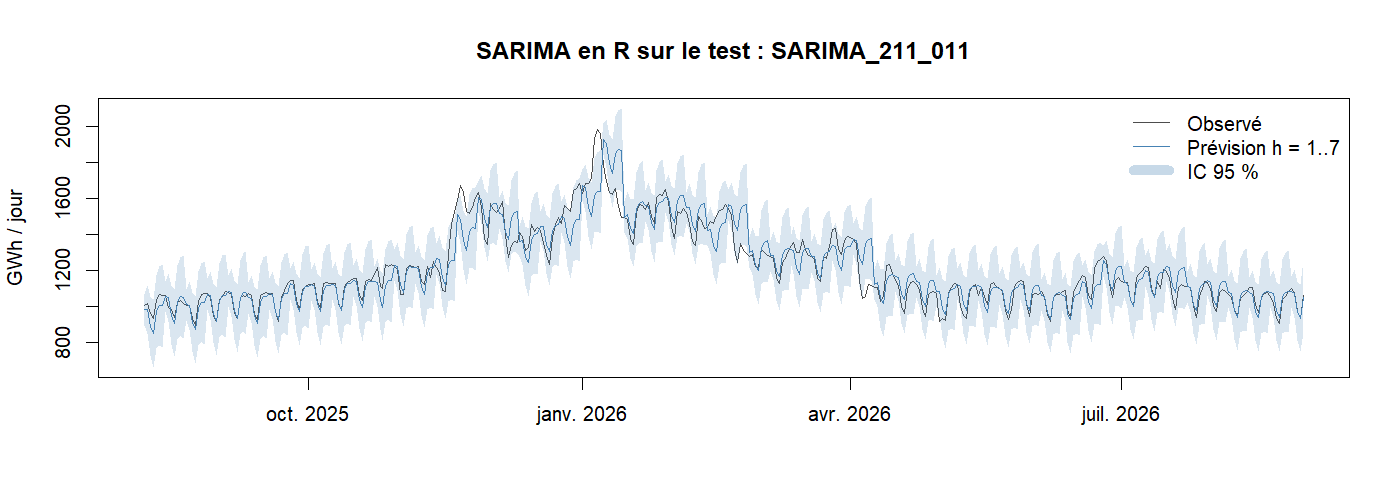

In [10]:
# évaluation sur le test externe (390 jours, blocs de 7 jours)
# Modèle figé AVANT le test : celui de plus petite RMSE en validation, comme en section 3.1
retenu <- comparaison$modele[grepl("^SARIMA", comparaison$modele)][1]
cat("Modèle retenu :", retenu, "\n")
fit_final <- fits[[retenu]]

# Paramètres estimés sur l'estimation, historique = train complet, origines tous les 7 jours
prev_test <- rolling_forecast(fit_final, train_df$conso_gwh, test_df$conso_gwh)
prev_test$date <- test_df$date[prev_test$i]
obs <- test_df$conso_gwh

scores_test <- rbind(
  data.frame(modele = paste0(retenu, "_R"), t(scores(obs, prev_test$prevision)),
             couverture_95 = mean(obs >= prev_test$borne_inferieure_95 & obs <= prev_test$borne_superieure_95)),
  data.frame(modele = "naif_saisonnier", t(scores(obs,
             naive_forecast(train_df$conso_gwh, obs))), couverture_95 = NA),
  data.frame(modele = "naif_derniere_valeur", t(scores(obs,
             naive_forecast(train_df$conso_gwh, obs, seasonal = FALSE))), couverture_95 = NA))
print(format(scores_test, digits = 5), row.names = FALSE)
write.csv(scores_test, "exports/R/scores_test_R.csv", row.names = FALSE)

# Format commun du groupe : forecasts/<modèle>.csv (date, prévision, borne basse, borne haute)
write.csv(prev_test[, c("date", "prevision", "borne_inferieure_95", "borne_superieure_95")],
          "forecasts/sarima_R.csv", row.names = FALSE, quote = FALSE)   # mêmes colonnes que forecasts/var.csv du notebook 05

# Graphique : observé vs prévu sur le test avec l'intervalle à 95 %
png("figures/R/sarima_test_R.png", width = 1400, height = 500, res = 120)
plot(test_df$date, obs, type = "l", col = "grey30", ylab = "GWh / jour", xlab = "",
     main = paste("SARIMA en R sur le test :", retenu),
     ylim = range(c(obs, prev_test$borne_inferieure_95, prev_test$borne_superieure_95)))
polygon(c(prev_test$date, rev(prev_test$date)), c(prev_test$borne_inferieure_95, rev(prev_test$borne_superieure_95)),
        col = adjustcolor("steelblue", 0.2), border = NA)
lines(prev_test$date, prev_test$prevision, col = "steelblue")
legend("topright", c("Observé", "Prévision h = 1..7", "IC 95 %"),
       col = c("grey30", "steelblue", adjustcolor("steelblue", 0.3)), lwd = c(1, 1, 8), bty = "n")
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/sarima_test_R.png")

### Lecture : R vs Python sur le test

| | Python | R |
|---|---:|---:|
| RMSE (GWh/jour) | 82,38 | 82,38 |
| MAE (GWh/jour) | 53,12 | 53,12 |
| Couverture IC 95 % | 94,36 % | 94,36 % |
| Naïf saisonnier, RMSE | 113,93 | 113,93 |

Les deux implémentations donnent les mêmes prévisions : le résultat ne dépend pas du logiciel.

## 9. Modèle retenu : diagnostics et prévision du 1er au 7 septembre 2026

In [11]:
# diagnostics du modèle retenu + prévision des 7 jours après le 31/08/2026
print(signif(diagnose(fit_final), 3))
# Réestimation sur toutes les données, puis prévision du 1er au 7 septembre 2026
fit_all <- Arima(to_ts(df$conso_gwh), order = arimaorder(fit_final)[1:3],
                 seasonal = list(order = arimaorder(fit_final)[4:6], period = 7), method = "ML")
fc7 <- forecast(fit_all, h = 7, level = 95)
prev7 <- data.frame(date = max(df$date) + 1:7, prevision = as.numeric(fc7$mean),
                    borne_inferieure_95 = as.numeric(fc7$lower), borne_superieure_95 = as.numeric(fc7$upper))
print(prev7, row.names = FALSE, digits = 6)
write.csv(prev7, "exports/R/previsions_7j_R.csv", row.names = FALSE)

   LB7_p   LB14_p       JB     JB_p  ARCH_LM   ARCH_p 
1.50e-10 1.59e-11 2.79e+03 0.00e+00 3.03e+02 1.32e-61 


       date prevision borne_inferieure_95 borne_superieure_95
 2026-09-01  1086.533            1002.273             1170.79
 2026-09-02  1090.597             960.404             1220.79
 2026-09-03  1085.842             924.188             1247.50
 2026-09-04  1074.401             889.990             1258.81
 2026-09-05   977.910             776.079             1179.74
 2026-09-06   938.228             722.373             1154.08
 2026-09-07  1056.446             828.823             1284.07


# Partie 2 — VAR, Johansen/VECM et GARCH : réplication du notebook 05

Objectif : refaire en R **exactement** les modèles de `05_var_vecm_garch_prophet.ipynb` (Python) pour vérifier que les résultats ne dépendent pas du logiciel.
Spécification reprise à l'identique :
- variables endogènes : consommation et **température moyenne** (`temp_moy`) ;
- exogènes de calendrier, connus à l'avance : 3 harmoniques de Fourier annuelles, 6 indicatrices de jour (lundi = référence), jour férié ;
- choix des ordres sur l'échantillon d'estimation, départage en validation interne (8 blocs de 7 jours), évaluation sur le test avec paramètres figés.

Prophet (modèle additionnel) n'est pas dans le périmètre de la section 3 et n'est pas répliqué.

## 10. Calendrier et stationnarité de la température

In [12]:
# partie 2, variables exogènes (spécification du notebook 05) et stationnarité
suppressPackageStartupMessages({
  library(vars)      # VAR, Granger, réponses impulsionnelles (≈ statsmodels VAR)
  library(urca)      # Johansen, VECM (≈ statsmodels coint_johansen / VECM)
  library(rugarch)   # GARCH (≈ package arch en Python)
})
cat("vars", as.character(packageVersion("vars")), "| urca", as.character(packageVersion("urca")),
    "| rugarch", as.character(packageVersion("rugarch")), "\n")

# Calendrier connu à l'avance, identique à build_exog() du notebook 05 :
# 3 harmoniques annuelles (jours depuis le 01/01/2016, période 365,25), mardi…dimanche (lundi = référence), férié
build_exog <- function(d) {
  t <- as.numeric(d$date - as.Date("2016-01-01"))
  fourier <- do.call(cbind, lapply(1:3, function(k) cbind(sin(2 * pi * k * t / 365.25), cos(2 * pi * k * t / 365.25))))
  colnames(fourier) <- paste0(c("sin", "cos"), rep(1:3, each = 2))
  dow <- sapply(1:6, function(j) as.numeric(d$jour_semaine == j))   # jour_semaine : 0 = lundi … 6 = dimanche
  colnames(dow) <- paste0("dow", 1:6)
  cbind(fourier, dow, ferie = d$ferie)
}
X_all <- build_exog(df)
Y_all <- cbind(conso_gwh = df$conso_gwh, temp_moy = df$temp_moy)   # variables endogènes, même ordre que le notebook 05
n_est <- nrow(est_df); N <- nrow(df)

# Stationnarité de la température sur l'apprentissage (la consommation est testée en partie 1)
a_t <- adf_test(train_df$temp_moy); k_t <- kpss_test(train_df$temp_moy)
cat(sprintf("temp_moy : ADF = %s (p %s) | KPSS = %.4f (p = %.3f)\n", a_t[["stat"]], a_t[["p"]], k_t[["stat"]], k_t[["p"]]))

Warning message:
"package 'vars' was built under R version 4.5.3"


Warning message:
"package 'strucchange' was built under R version 4.5.3"
Warning message:
"package 'zoo' was built under R version 4.5.3"
Warning message:
"package 'sandwich' was built under R version 4.5.3"
Warning message:
"package 'rugarch' was built under R version 4.5.3"


vars 1.6.1 | urca 1.3.4 | rugarch 1.5.6 
temp_moy : ADF = -3.478 (p < 0.01) | KPSS = 0.0751 (p = 0.100)


### Lecture
Mêmes résultats qu'en Python : ADF = −3,478 et KPSS = 0,0751 pour la température, qui est donc **stationnaire**, comme la consommation.
La fonction ADF reproduit la procédure de statsmodels : les retards sont choisis par AIC sur un échantillon commun, puis la régression est refaite sur tout l'échantillon. Une première version basée sur `urca::ur.df` donnait −3,37 : `ur.df` garde l'échantillon réduit.

## 11. Ordre du VAR : critères d'information puis validation interne

In [13]:
# ordre du VAR (AIC/BIC/HQ) puis choix par validation interne
# Critères calculés sur l'échantillon d'estimation (3 450 jours), retards 1 à 21
sel <- VARselect(Y_all[1:n_est, ], lag.max = 21, type = "const", exogen = X_all[1:n_est, ])
print(sel$selection)

# Outils de prévision glissante communs au VAR et au VECM (paramètres figés, blocs de 7 jours)
var_recursif <- function(A, D, y_hist, x_fut, h) {
  # y_t = A1 y_{t-1} + … + Ap y_{t-p} + D x_t  (x_t = constante + calendrier)
  K <- ncol(y_hist); p <- length(A); y <- y_hist; out <- matrix(NA, h, K)
  for (s in 1:h) {
    yt <- D %*% x_fut[s, ]
    for (i in 1:p) yt <- yt + A[[i]] %*% y[nrow(y) - i + 1, ]
    y <- rbind(y, t(yt)); out[s, ] <- yt
  }
  out
}
wf_var <- function(A, D, Phis, Sigma, start, end, h = H) {
  # écart-type de l'erreur à h pas : racine de Σ_{i<h} Φi Σ Φi' (élément de la consommation)
  sd_h <- sqrt(cumsum(sapply(1:h, function(i) (Phis[, , i] %*% Sigma %*% t(Phis[, , i]))[1, 1])))
  out <- NULL
  for (s in seq(start, end, by = h)) {
    idx <- s:min(s + h - 1, end)
    f <- var_recursif(A, D, Y_all[1:(s - 1), ], cbind(1, X_all[idx, , drop = FALSE]), length(idx))[, 1]
    sd <- sd_h[seq_along(idx)]
    out <- rbind(out, data.frame(date = df$date[idx], observe = df$conso_gwh[idx], prevision = f,
                                 borne_inferieure_95 = f - qnorm(0.975) * sd, borne_superieure_95 = f + qnorm(0.975) * sd))
  }
  out
}
metriques <- function(p) c(RMSE = sqrt(mean((p$observe - p$prevision)^2)), MAE = mean(abs(p$observe - p$prevision)),
                           MAPE = 100 * mean(abs((p$observe - p$prevision) / p$observe)),
                           couverture_95 = mean(p$observe >= p$borne_inferieure_95 & p$observe <= p$borne_superieure_95),
                           largeur_95 = mean(p$borne_superieure_95 - p$borne_inferieure_95))
parts_var <- function(v) {                         # coefficients d'un objet vars::VAR au format de var_recursif
  B <- Bcoef(v)
  list(A = lapply(1:v$p, function(i) B[, paste0(colnames(Y_all), ".l", i)]), D = B[, c("const", colnames(X_all))],
       Phi = Phi(v, nstep = H - 1), Sigma = summary(v)$covres)
}

# Règle du notebook 05 : candidats = ordres AIC, BIC, HQ ; on garde la plus petite RMSE de validation
cand_p <- sort(unique(sel$selection[c("AIC(n)", "SC(n)", "HQ(n)")]))
var_val <- t(sapply(cand_p, function(p) {
  z <- parts_var(VAR(Y_all[1:n_est, ], p = p, type = "const", exogen = X_all[1:n_est, ]))
  c(p = p, metriques(wf_var(z$A, z$D, z$Phi, z$Sigma, n_est + 1, n_train))[c("RMSE", "MAE")])
}))
print(round(var_val, 3))
P_VAR <- var_val[which.min(var_val[, "RMSE"]), "p"]
cat("Ordre retenu :", P_VAR, "\n")
write.csv(var_val, "exports/R/var_validation_R.csv", row.names = FALSE)

AIC(n)  HQ(n)  SC(n) FPE(n) 
    13      9      3     13 
      p   RMSE    MAE
[1,]  3 48.366 38.661
[2,]  9 48.527 36.432
[3,] 13 48.738 37.496
Ordre retenu : 3 


### Lecture
Les critères sont identiques à Python (AIC 13, HQ 9, BIC 3), ainsi que les RMSE de validation des trois candidats (48,366 / 48,527 / 48,738). On retient donc **VAR(3)**, le plus parcimonieux, avec la même règle que le notebook 05.

## 12. VAR(3) : stabilité et diagnostics des résidus

In [14]:
# VAR final sur tout l'apprentissage, stabilité et diagnostics
var_fit <- VAR(Y_all[1:n_train, ], p = P_VAR, type = "const", exogen = X_all[1:n_train, ])
mod <- roots(var_fit)                               # modules des valeurs propres de la matrice compagnon
cat(sprintf("Stabilité : module maximal = %.4f (< 1 : stable) ; module minimal = %.4f\n", max(mod), min(mod)))

diag_eq <- function(e, nom) {                       # mêmes tests que diagnostics() du notebook 05
  c(LB7_p = Box.test(e, 7, "Ljung-Box")$p.value, LB14_p = Box.test(e, 14, "Ljung-Box")$p.value,
    JB_p = jarque.bera.test(e)$p.value, kurtosis = mean((e - mean(e))^4) / mean((e - mean(e))^2)^2,
    ARCH_p = arch_lm(e, 7)[["ARCH_p"]])
}
diag_var <- rbind(conso_gwh = diag_eq(residuals(var_fit)[, "conso_gwh"]),
                  temp_moy  = diag_eq(residuals(var_fit)[, "temp_moy"]))
print(signif(diag_var, 3))
pt <- serial.test(var_fit, lags.pt = 14, type = "PT.adjusted")$serial
nt <- normality.test(var_fit, multivariate.only = TRUE)$jb.mul$JB
cat(sprintf("Portmanteau multivarié (14 retards) : %.1f (p = %.3g) | Jarque-Bera multivarié : %.1f (p = %.3g)\n",
            pt$statistic, pt$p.value, nt$statistic, nt$p.value))
cat("Corrélation des résidus conso / température :", round(cor(residuals(var_fit))[1, 2], 3), "\n")
write.csv(diag_var, "exports/R/diagnostics_var_R.csv")

Stabilité : module maximal = 0.8656 (< 1 : stable) ; module minimal = 0.2548
          LB7_p LB14_p    JB_p kurtosis   ARCH_p
conso_gwh 0.000 0.0000 0.0e+00     5.79 7.04e-32
temp_moy  0.129 0.0791 1.7e-09     3.48 5.77e-04
Portmanteau multivarié (14 retards) : 351.1 (p = 0) | Jarque-Bera multivarié : 1268.3 (p = 0)
Corrélation des résidus conso / température : -0.463 


### Lecture
- **Stabilité** : le module **maximal** des valeurs propres vaut **0,866** (< 1), donc le VAR est stable.
  ⚠️ **Point de relecture croisée** : le notebook Python affiche « module max des racines = 0,2548 ». C'est en réalité le module **minimal** (0,2548, retrouvé ici) : `np.max(np.abs(var_res.roots)) ** -1` prend l'inverse de la plus grande racine du polynôme, ce qui donne la plus petite valeur propre. La conclusion (stable) ne change pas, mais il faut corriger le chiffre dans le rapport.
- **Diagnostics** : identiques à Python. L'équation de la consommation garde de l'autocorrélation, des queues épaisses (kurtosis 5,8) et un effet ARCH. L'équation de la température est propre en autocorrélation (Ljung-Box p = 0,13). Portmanteau multivarié 351,1, Jarque-Bera multivarié 1 268,3, corrélation des résidus −0,463 : tout coïncide.

## 13. Causalité de Granger et réponse impulsionnelle
Pour la réponse impulsionnelle (Cholesky), la température est placée en premier, comme dans le notebook 05 : un choc de température peut affecter la consommation le jour même, l'inverse non.

                 sens       F     ddl  p_value
 temp_moy → conso_gwh 118.573 3, 6966 0.000000
 conso_gwh → temp_moy   6.606 3, 6966 0.000187
Causalité instantanée : chi2 = 618.1 (p = 0)
      p p_temp_vers_conso p_conso_vers_temp
[1,]  1                 0          2.64e-02
[2,]  3                 0          1.87e-04
[3,]  7                 0          9.88e-04
[4,]  9                 0          1.56e-04
[5,] 13                 0          4.93e-05
Écart-type du choc de température : 1.25 °C
Réponse (GWh/jour), jours 0 à 7 : -17.2 -29.4 -29.4 -24.7 -20.8 -18.3 -16.3 -14.5 


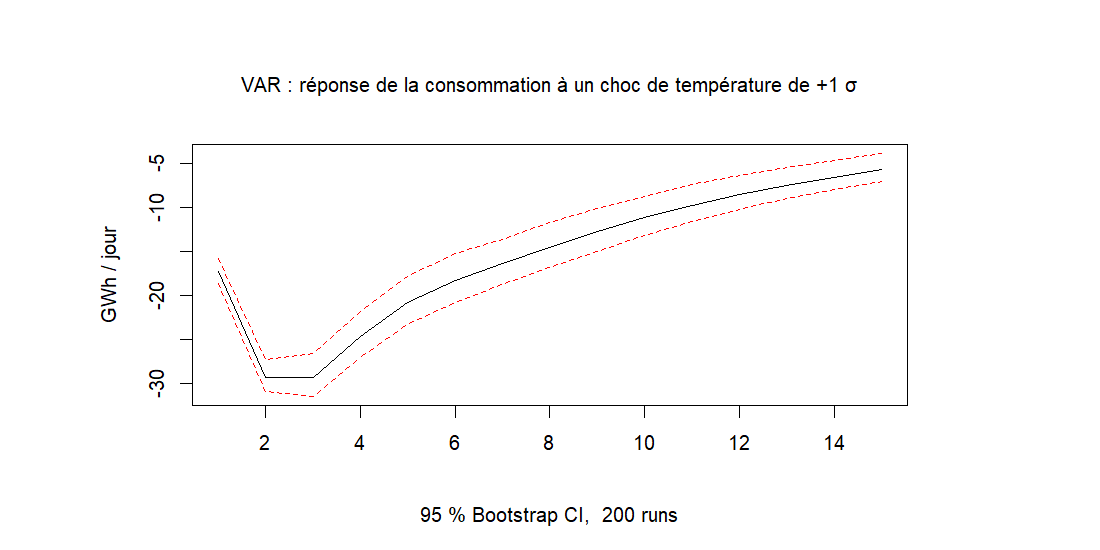

In [15]:
# causalité de Granger, robustesse à l'ordre et réponse impulsionnelle
g_tc <- causality(var_fit, cause = "temp_moy")      # température → consommation
g_ct <- causality(var_fit, cause = "conso_gwh")     # consommation → température
granger <- data.frame(sens = c("temp_moy → conso_gwh", "conso_gwh → temp_moy"),
                      F = round(c(g_tc$Granger$statistic, g_ct$Granger$statistic), 3),
                      ddl = rep(paste(g_tc$Granger$parameter, collapse = ", "), 2),
                      p_value = signif(c(g_tc$Granger$p.value, g_ct$Granger$p.value), 3))
print(granger, row.names = FALSE)
cat(sprintf("Causalité instantanée : chi2 = %.1f (p = %.3g)\n", g_ct$Instant$statistic, g_ct$Instant$p.value))

rob <- t(sapply(sort(unique(c(1, 3, 7, 9, 13))), function(p) {
  v <- VAR(Y_all[1:n_train, ], p = p, type = "const", exogen = X_all[1:n_train, ])
  c(p = p, p_temp_vers_conso = causality(v, cause = "temp_moy")$Granger$p.value,
    p_conso_vers_temp = causality(v, cause = "conso_gwh")$Granger$p.value)
}))
print(signif(rob, 3))
write.csv(granger, "exports/R/granger_R.csv", row.names = FALSE)

# Réponse de la consommation à un choc de température de +1 écart-type (Cholesky, température en premier)
var_irf <- VAR(Y_all[1:n_train, 2:1], p = P_VAR, type = "const", exogen = X_all[1:n_train, ])
ir <- irf(var_irf, impulse = "temp_moy", response = "conso_gwh", n.ahead = 14, boot = TRUE, runs = 200, seed = 42)
rep_c <- ir$irf$temp_moy[, 1]
cat("Écart-type du choc de température :", round(sqrt(summary(var_irf)$covres[1, 1]), 2), "°C\n")
cat("Réponse (GWh/jour), jours 0 à 7 :", round(rep_c[1:8], 1), "\n")
png("figures/R/var_irf_R.png", width = 1100, height = 550, res = 120)
plot(ir, main = "VAR : réponse de la consommation à un choc de température de +1 σ",
     ylab = "GWh / jour", xlab = "jours après le choc")
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/var_irf_R.png")

### Lecture
- **Granger** : F = 118,57 (température → consommation) et F = 6,61 (consommation → température), avec ddl (3 ; 6 966). Ce sont exactement les valeurs Python, et la robustesse aux ordres 1 à 13 est la même.
- Le sens inverse est significatif mais **physiquement impossible** : la consommation ne fait pas la météo. Granger mesure une amélioration de prévision, pas une causalité physique. Avec 3 500 observations, de très petits effets deviennent significatifs. On retient l'**asymétrie** (statistique 18 fois plus forte dans le sens physique).
- **Causalité instantanée** : χ² = 618,1. Les chocs du même jour sont corrélés (−0,46).
- **Réponse impulsionnelle** : −17,2 GWh le jour même, −29,4 GWh au pic (jours 1-2), −14,5 au 7e jour, pour un choc de +1,25 °C. Les valeurs sont identiques à Python.

## 14. Prévisions du VAR sur le test externe

In [16]:
# prévisions du VAR sur le test externe
z_var <- parts_var(var_fit)
pred_var <- wf_var(z_var$A, z_var$D, z_var$Phi, z_var$Sigma, n_train + 1, N)
print(round(metriques(pred_var), 3))
cols_fc <- c("date", "prevision", "borne_inferieure_95", "borne_superieure_95")   # format commun du groupe
write.csv(pred_var[, cols_fc], "forecasts/var_R.csv", row.names = FALSE, quote = FALSE)

         RMSE           MAE          MAPE couverture_95    largeur_95 
       78.957        54.670         4.306         0.931       277.975 


### Lecture
RMSE 78,96, MAE 54,67, couverture 93,1 %, largeur moyenne 278 GWh : **identique à Python au centième**. Le VAR(3) bat le SARIMA de la section 3.1 (82,4) parce qu'il dispose du calendrier (Fourier annuel, fériés), alors même qu'il doit prévoir lui-même la température.

## 15. Test de cointégration de Johansen
Équivalence des options : `coint_johansen(det_order = 0, k_ar_diff = 2)` en Python correspond à `ca.jo(ecdet = "none", K = 3)` en R, soit une constante non restreinte et K = k_ar_diff + 1 retards en niveau.

In [17]:
# test de cointégration de Johansen
# Spécification du notebook 05 : données brutes, constante non restreinte, 2 retards en différences (K = 3 en niveau)
jo_tr <- ca.jo(Y_all[1:n_train, ], type = "trace", ecdet = "none", K = 3, spec = "transitory")
jo_ei <- ca.jo(Y_all[1:n_train, ], type = "eigen", ecdet = "none", K = 3, spec = "transitory")
johansen <- data.frame(H0 = c("r ≤ 1", "r = 0"), trace = round(jo_tr@teststat, 2), crit_trace_5 = jo_tr@cval[, "5pct"],
                       lambda_max = round(jo_ei@teststat, 2), crit_lambda_5 = jo_ei@cval[, "5pct"])
print(johansen, row.names = FALSE)

# Sensibilité : données brutes ou corrigées du calendrier, 1 à 13 retards, constante libre ou dans la relation
adj <- apply(Y_all[1:n_train, ], 2, function(y) residuals(lm(y ~ X_all[1:n_train, ])))
rang <- function(Y, ecdet, K) { j <- ca.jo(Y, type = "trace", ecdet = ecdet, K = K, spec = "transitory")
  sum(cumprod(rev(j@teststat) > rev(j@cval[, "5pct"]))) }   # rejets successifs de r = 0, r ≤ 1
sens <- expand.grid(donnees = c("brutes", "corrigées"), ecdet = c("none", "const"), k_ar_diff = c(1, 2, 7, 13),
                    stringsAsFactors = FALSE)
sens$rang <- mapply(function(d, e, k) rang(if (d == "brutes") Y_all[1:n_train, ] else adj, e, k + 1),
                    sens$donnees, sens$ecdet, sens$k_ar_diff)
print(xtabs(rang ~ paste(donnees, ecdet) + k_ar_diff, sens))
write.csv(johansen, "exports/R/johansen_R.csv", row.names = FALSE)

    H0  trace crit_trace_5 lambda_max crit_lambda_5
 r ≤ 1  39.55         8.18      39.55          8.18
 r = 0 337.72        17.95     298.17         14.90
                     k_ar_diff
paste(donnees, ecdet) 1 2 7 13
      brutes const    2 2 2  2
      brutes none     2 2 2  2
      corrigées const 2 2 2  2
      corrigées none  2 2 2  2


### Lecture
Statistiques identiques à Python (trace 337,7 et 39,6 ; λ-max 298,2). Les **valeurs critiques diffèrent** (8,18 en R, 3,84 en Python pour r ≤ 1), car les deux logiciels utilisent des tables différentes (Osterwald-Lenum en R, MacKinnon et al. en Python). La conclusion ne change pas : r = 0 et r ≤ 1 sont rejetés.
**Rang plein (r = 2)** dans toutes les variantes testées (données brutes ou corrigées du calendrier, 1 à 13 retards, constante libre ou restreinte) : les deux séries sont stationnaires, et il n'y a **pas de cointégration au sens strict**.

## 16. VECM (r = 1 imposé) : retards, relation de long terme, vitesse de correction
`VECM(deterministic = "co")` en Python correspond à `ca.jo(ecdet = "none")` + `cajorls()` en R : la constante est hors de la relation de cointégration, et le calendrier entre en régresseur exogène.

In [18]:
# VECM (r = 1 imposé) : choix des retards, relation de long terme, vitesse de correction
# Constante hors de la relation et calendrier en exogène (deterministic = "co" dans le notebook 05)
fit_vecm <- function(n, k) ca.jo(Y_all[1:n, ], type = "trace", ecdet = "none", K = k + 1,
                                 dumvar = X_all[1:n, ], spec = "transitory")
vecm_parts <- function(jo) { vv <- vec2var(jo, r = 1)
  list(A = vv$A, D = vv$deterministic, Phi = Phi(vv, nstep = H - 1),
       Sigma = crossprod(vv$resid) / nrow(vv$resid), resid = vv$resid) }

cand_k <- c(2, 8, 12)                               # retards proposés par BIC, HQ et AIC dans le notebook 05
vecm_val <- t(sapply(cand_k, function(k) { z <- vecm_parts(fit_vecm(n_est, k))
  c(k_ar_diff = k, metriques(wf_var(z$A, z$D, z$Phi, z$Sigma, n_est + 1, n_train))[c("RMSE", "MAE")]) }))
print(round(vecm_val, 3))
K_VECM <- vecm_val[which.min(vecm_val[, "RMSE"]), "k_ar_diff"]

vecm_coef <- function(k) {
  cr <- cajorls(fit_vecm(n_train, k), r = 1)
  tab <- coef(summary(cr$rlm))
  a_c <- tab[["Response conso_gwh.d"]]["ect1", ]; a_t <- tab[["Response temp_moy.d"]]["ect1", ]
  c(k_ar_diff = k, beta_temp = cr$beta["temp_moy.l1", 1], alpha_conso = a_c[["Estimate"]], p_alpha_conso = a_c[["Pr(>|t|)"]],
    alpha_temp = a_t[["Estimate"]], p_alpha_temp = a_t[["Pr(>|t|)"]],
    demi_vie = if (a_c[["Estimate"]] < 0) log(0.5) / log(1 + a_c[["Estimate"]]) else NA)
}
rob_vecm <- t(sapply(cand_k, vecm_coef))
print(signif(rob_vecm, 4))
ret <- rob_vecm[rob_vecm[, "k_ar_diff"] == K_VECM, ]
cat(sprintf("\nVECM retenu (k = %d) : conso + %.2f × température = constante ; α_conso = %.4f, demi-vie ≈ %.1f jours\n",
            K_VECM, ret[["beta_temp"]], ret[["alpha_conso"]], ret[["demi_vie"]]))
write.csv(rob_vecm, "exports/R/vecm_robustesse_R.csv", row.names = FALSE)

     k_ar_diff   RMSE    MAE
[1,]         2 55.482 44.936
[2,]         8 62.375 39.495
[3,]        12 53.439 40.623
     k_ar_diff beta_temp alpha_conso p_alpha_conso alpha_temp p_alpha_temp
[1,]         2     61.77   -0.052180     6.815e-19  -0.002612    2.566e-40
[2,]         8    134.10    0.007246     2.922e-02  -0.001685    9.704e-52
[3,]        12     82.08   -0.018110     4.341e-03  -0.002324    2.790e-27
     demi_vie
[1,]    12.93
[2,]       NA
[3,]    37.92

VECM retenu (k = 12) : conso + 82.08 × température = constante ; α_conso = -0.0181, demi-vie ≈ 37.9 jours


### Lecture
- Les RMSE de validation sont identiques (55,48 / 62,38 / 53,44), d'où **k = 12** comme dans le notebook 05.
- **Relation de long terme** : conso + 82,08 × T = constante, soit environ −82 GWh/jour par degré supplémentaire.
- **Vitesse de correction** : α_conso = −0,0181 (p = 0,004). Chaque jour, 1,8 % de l'écart à l'équilibre est résorbé, soit une **demi-vie d'environ 38 jours**.
- **Robustesse faible**, également identique à Python : α_conso vaut −0,052 (k = 2), **+0,007** (k = 8, aucune correction) ou −0,018 (k = 12), et β varie de 62 à 134. Comme le rang est plein, la relation imposée (r = 1) n'est pas identifiée de façon stable. La vitesse de correction n'est qu'**indicative**.

## 17. VECM : diagnostics et prévisions

In [19]:
# VECM, diagnostics et prévisions sur le test externe
z_vecm <- vecm_parts(fit_vecm(n_train, K_VECM))
diag_vecm <- rbind(conso_gwh = diag_eq(z_vecm$resid[, 1]), temp_moy = diag_eq(z_vecm$resid[, 2]))
print(signif(diag_vecm, 3))
write.csv(diag_vecm, "exports/R/diagnostics_vecm_R.csv")
pred_vecm <- wf_var(z_vecm$A, z_vecm$D, z_vecm$Phi, z_vecm$Sigma, n_train + 1, N)
print(round(metriques(pred_vecm), 3))
write.csv(pred_vecm[, cols_fc], "forecasts/vecm_R.csv", row.names = FALSE, quote = FALSE)

             LB7_p   LB14_p     JB_p kurtosis   ARCH_p
conso_gwh 7.77e-16 2.22e-16 0.00e+00     5.77 6.94e-26
temp_moy  1.00e+00 1.00e+00 3.91e-08     3.44 1.70e-05
         RMSE           MAE          MAPE couverture_95    largeur_95 
       87.562        58.706         4.606         0.913       293.854 


### Lecture
RMSE 87,56, couverture 91,3 %, largeur 294 GWh : identique à Python. Le VECM est moins bon que le VAR(3) (78,96), ce qui est cohérent avec le rang plein : imposer une relation de cointégration qui n'existe pas dégrade la prévision.

## 18. GARCH sur les écarts à la saisonnalité
Mêmes étapes que le notebook 05 : (1) saisonnalité = régression sur le calendrier, (2) moyenne AR creuse choisie par BIC, (3) comparaison de 8 GARCH (ordres (1,1) à (2,2), lois normale et Student) par BIC.

**Choix technique.** Avec un AR(14) aux coefficients contraints à zéro, le solveur de rugarch convergeait mal et de façon **non reproductible** : le solveur `hybrid` fait des redémarrages aléatoires, et la vraisemblance changeait d'une exécution à l'autre. On passe donc les 5 retards en régresseurs de la moyenne, sur l'échantillon qui commence au 15e jour. C'est le même modèle, et c'est la formulation du package `arch` en Python. L'estimation est maintenant stable et prend environ 3 secondes par modèle.

In [20]:
# GARCH, écarts à la saisonnalité, moyenne AR et comparaison des modèles
# Saisonnalité = régression sur le calendrier, estimée sur l'apprentissage puis figée pour le test
saison_cal <- lm(df$conso_gwh[1:n_train] ~ X_all[1:n_train, ])
seas_all <- as.numeric(cbind(1, X_all) %*% coef(saison_cal))
ecart <- df$conso_gwh - seas_all                    # écart à la saisonnalité (apprentissage + test)
e_tr <- ecart[1:n_train]
cat(sprintf("R² du calendrier : %.3f ; écart-type des écarts : %.1f GWh ; ARCH-LM p = %.3g\n",
            summary(saison_cal)$r.squared, sd(e_tr), arch_lm(e_tr - mean(e_tr), 7)[["ARCH_p"]]))

# Moyenne autorégressive : candidats du notebook 05, BIC de chaque AR estimé par MCO sur son propre échantillon
cands_ar <- list("AR(1)" = 1, "AR(2)" = 1:2, "AR(7)" = 1:7, "AR(8)" = 1:8, "AR(14)" = 1:14, "AR(21)" = 1:21,
                 "AR[1,2,7]" = c(1, 2, 7), "AR[1,2,7,8]" = c(1, 2, 7, 8), "AR[1,2,7,8,14]" = c(1, 2, 7, 8, 14),
                 "AR[1,2,3,7,8,14]" = c(1, 2, 3, 7, 8, 14))
bic_ar <- sapply(cands_ar, function(l) { Z <- embed(e_tr, max(l) + 1); BIC(lm(Z[, 1] ~ Z[, l + 1])) })
print(round(sort(bic_ar), 1))
AR_LAGS <- cands_ar[[names(which.min(bic_ar))]]
ZERO <- setdiff(1:max(AR_LAGS), AR_LAGS)            # retards absents de l'AR creux (coefficients fixés à 0)

# GARCH en centaines de GWh (même mise à l'échelle que le notebook 05, pour la stabilité de l'optimiseur).
# Les retards de l'AR creux entrent comme régresseurs de la moyenne, sur l'échantillon qui commence au 15e jour :
# c'est la formulation du package arch en Python (14 premières observations mises de côté), et l'optimiseur
# de rugarch converge de façon fiable et déterministe (le solveur "hybrid" avec un AR(14) contraint ne l'était pas).
SC <- 100
P_MAX <- max(AR_LAGS)
lag_mat <- function(x, rows) sapply(AR_LAGS, function(l) x[rows - l])      # matrice des retards de l'écart
rows_tr <- (P_MAX + 1):n_train
R_tr <- lag_mat(e_tr / SC, rows_tr); colnames(R_tr) <- paste0("l", AR_LAGS)
spec_g <- function(a, b, dist, R) ugarchspec(
  variance.model = list(model = "sGARCH", garchOrder = c(a, b)),   # a termes ARCH (α), b termes GARCH (β)
  mean.model = list(armaOrder = c(0, 0), include.mean = TRUE, external.regressors = R),
  distribution.model = dist)
garch_fits <- list(); comp_g <- NULL
for (dist in c("norm", "std")) for (o in list(c(1, 1), c(2, 1), c(1, 2), c(2, 2))) {
  nom <- sprintf("GARCH(%d,%d)-%s", o[1], o[2], ifelse(dist == "std", "t", "normal"))
  f <- ugarchfit(spec_g(o[1], o[2], dist, R_tr), e_tr[rows_tr] / SC, solver = "solnp")
  garch_fits[[nom]] <- f
  comp_g <- rbind(comp_g, data.frame(modele = nom, logL = likelihood(f),
                                     BIC = -2 * likelihood(f) + length(coef(f)) * log(length(rows_tr)),
                                     persistance = persistence(f), nu = if (dist == "std") coef(f)[["shape"]] else NA))
}
print(format(comp_g, digits = 5), row.names = FALSE)
write.csv(comp_g, "exports/R/comparaison_garch_R.csv", row.names = FALSE)
G_NOM <- comp_g$modele[which.min(comp_g$BIC)]
g_fit <- garch_fits[[G_NOM]]
cat("\nMeilleur BIC :", G_NOM, "\n"); print(round(coef(g_fit), 4))

R² du calendrier : 0.823 ; écart-type des écarts : 106.3 GWh ; ARCH-LM p = 0
  AR[1,2,7,8,14] AR[1,2,3,7,8,14]           AR(21)           AR(14) 
         35533.9          35541.0          35565.4          35597.8 
     AR[1,2,7,8]            AR(8)        AR[1,2,7]            AR(7) 
         35618.7          35648.4          35712.6          35741.1 
           AR(2)            AR(1) 
         35755.0          35912.9 
            modele     logL    BIC persistance     nu
 GARCH(1,1)-normal -1146.47 2366.4     0.99898     NA
 GARCH(2,1)-normal -1148.00 2377.6     0.99887     NA
 GARCH(1,2)-normal -1136.53 2354.6     0.98467     NA
 GARCH(2,2)-normal -1136.53 2362.8     0.98467     NA
      GARCH(1,1)-t  -874.75 1831.1     0.99900 4.0835
      GARCH(2,1)-t  -875.05 1839.8     0.99900 4.0784
      GARCH(1,2)-t  -858.50 1806.7     0.99900 4.0973
      GARCH(2,2)-t  -858.50 1814.9     0.99900 4.0973

Meilleur BIC : GARCH(1,2)-t 
     mu  mxreg1  mxreg2  mxreg3  mxreg4  mxreg5   omega  alph

### Lecture
- La saisonnalité calendrier explique 82,3 % de la variance (écart-type des écarts : 106,3 GWh). Le classement BIC des AR est **identique** à Python, avec le meilleur modèle **AR[1,2,7,8,14]** (35 533,9).
- Même modèle retenu : **GARCH(1,2) Student**. Ses paramètres sont quasi identiques (α₁ = 0,336 contre 0,337 ; β₁ + β₂ = 0,663 ; ν = 4,10). Les log-vraisemblances sont proches de celles de Python (−858,5 contre −857,4), le petit écart venant de l'initialisation de la variance, qui diffère entre `arch` et `rugarch`.
- La loi de Student améliore très nettement l'ajustement (≈ +270 de log-vraisemblance) : les queues sont épaisses (ν ≈ 4).
- Persistance α + β ≈ 0,999, presque un IGARCH : la volatilité est surtout saisonnière (plus forte en hiver), ce que le GARCH traduit par une mémoire très longue.
- Seule bizarrerie : GARCH(2,1)-normal a une vraisemblance un peu plus faible que GARCH(1,1)-normal, alors qu'il le contient. L'optimiseur s'arrête sur un optimum local. C'est sans conséquence, ce modèle n'étant pas retenu.

## 19. Diagnostics des résidus standardisés

                                      LB_z7 LB_z14  LB_z2_7 LB_z2_14 JB_p
AR creux, variance constante (témoin) 0.848  0.695 0.00e+00  0.00000    0
GARCH(1,1)-normal                     0.885  0.930 1.18e-04  0.00627    0
GARCH(1,1)-t                          0.585  0.491 2.58e-05  0.00122    0
GARCH(1,2)-t (retenu)                 0.702  0.602 5.52e-02  0.27700    0
                                      kurtosis   ARCH_p
AR creux, variance constante (témoin)     7.39 2.03e-85
GARCH(1,1)-normal                         8.09 1.64e-04
GARCH(1,1)-t                              9.07 3.89e-05
GARCH(1,2)-t (retenu)                    10.10 6.23e-02


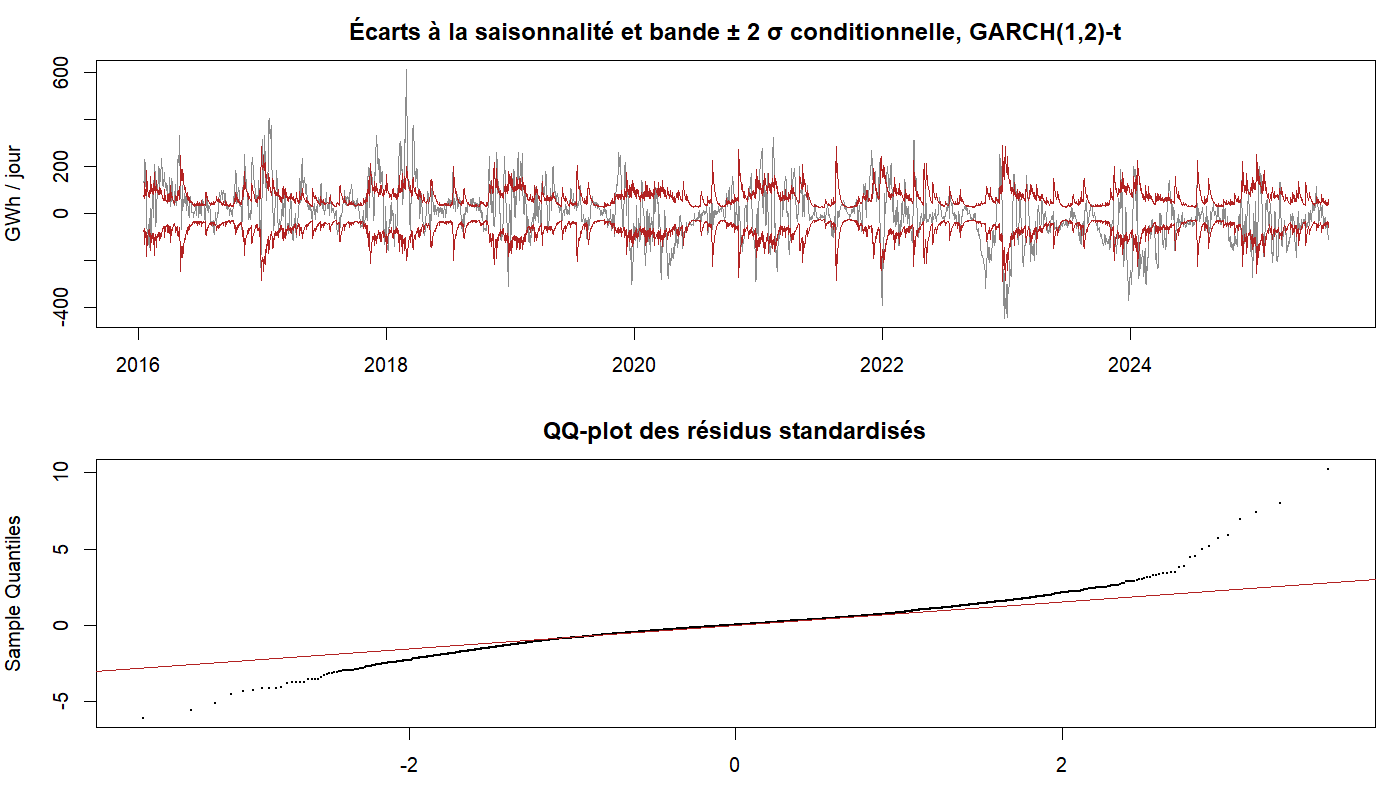

In [21]:
# diagnostics des résidus standardisés (avec un témoin à variance constante)
# Témoin : même AR creux estimé par MCO, variance constante
ols_ar <- lm(e_tr[rows_tr] ~ lag_mat(e_tr, rows_tr))
garch_diag <- function(z) c(LB_z7 = Box.test(z, 7, "Ljung-Box")$p.value, LB_z14 = Box.test(z, 14, "Ljung-Box")$p.value,
                            LB_z2_7 = Box.test(z^2, 7, "Ljung-Box")$p.value, LB_z2_14 = Box.test(z^2, 14, "Ljung-Box")$p.value,
                            JB_p = jarque.bera.test(z)$p.value, kurtosis = mean((z - mean(z))^4) / var(z)^2,
                            ARCH_p = arch_lm(z, 7)[["ARCH_p"]])
z_std <- function(f) as.numeric(residuals(f, standardize = TRUE))
diag_g <- rbind("AR creux, variance constante (témoin)" = garch_diag(residuals(ols_ar) / sd(residuals(ols_ar))),
                "GARCH(1,1)-normal" = garch_diag(z_std(garch_fits[["GARCH(1,1)-normal"]])),
                "GARCH(1,1)-t" = garch_diag(z_std(garch_fits[["GARCH(1,1)-t"]])),
                retenu = garch_diag(z_std(g_fit)))
rownames(diag_g)[4] <- paste(G_NOM, "(retenu)")
print(signif(diag_g, 3))
write.csv(diag_g, "exports/R/diagnostics_garch_R.csv")

png("figures/R/garch_R.png", width = 1400, height = 800, res = 120)
par(mfrow = c(2, 1), mar = c(3, 4, 2.5, 1))
plot(train_df$date[rows_tr], e_tr[rows_tr], type = "l", col = "grey55", ylab = "GWh / jour", xlab = "",
     main = paste("Écarts à la saisonnalité et bande ± 2 σ conditionnelle,", G_NOM))
s_g <- as.numeric(sigma(g_fit)) * SC
lines(train_df$date[rows_tr], 2 * s_g, col = "firebrick"); lines(train_df$date[rows_tr], -2 * s_g, col = "firebrick")
qqnorm(z_std(g_fit), main = "QQ-plot des résidus standardisés", pch = 20, cex = 0.4); qqline(z_std(g_fit), col = "firebrick")
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/garch_R.png")

### Lecture
Même tableau qu'en Python : la moyenne est bien spécifiée (Ljung-Box sur z : p ≈ 0,7), et seul le GARCH(1,2)-t capte l'effet ARCH (Ljung-Box sur z² : p = 0,055 et 0,277 ; témoin : p ≈ 0). Jarque-Bera rejette encore (kurtosis ≈ 10) : même une loi de Student n'absorbe pas tous les jours extrêmes (fériés atypiques, vagues de froid).

## 20. Prévisions AR-GARCH et témoin à variance constante
Prévision = saisonnalité figée + prévision AR de l'écart. Variance de l'erreur à h pas = Σ ψⱼ² σ²ₜ₊ₕ₋ⱼ, où les ψⱼ sont les poids MA de l'AR et les σ² sont prévus par le GARCH. Le témoin (même moyenne, variance constante) isole l'apport du GARCH.
Le filtre GARCH initialise sa variance sur l'apprentissage seulement (`n.old`), pour ne laisser entrer aucune information du test.

In [22]:
# prévisions glissantes AR-GARCH et témoin sur le test externe
# Prévision = saisonnalité figée + prévision AR de l'écart ;
# variance de l'erreur à h pas = Σ ψj² σ²_{t+h-j} (ψ = poids MA de l'AR, σ² prévus par le GARCH)
cf_g <- coef(g_fit)
phi_g <- rep(0, P_MAX); phi_g[AR_LAGS] <- cf_g[paste0("mxreg", seq_along(AR_LAGS))]
psi_g <- c(1, ARMAtoMA(ar = phi_g, lag.max = H - 1))
alpha_g <- cf_g[grep("^alpha", names(cf_g))]; beta_g <- cf_g[grep("^beta", names(cf_g))]

# Filtre GARCH à paramètres figés sur toute la série : σ_t ne dépend que du passé ;
# la variance initiale est calculée sur l'apprentissage seulement (n.old), sans information du test
rows_all <- (P_MAX + 1):N
R_all <- lag_mat(ecart / SC, rows_all); colnames(R_all) <- colnames(R_tr)
spec_fixe <- spec_g(1, 2, "std", R_all); setfixed(spec_fixe) <- as.list(cf_g)
filt <- ugarchfilter(spec_fixe, ecart[rows_all] / SC, n.old = length(rows_tr))
sig2_f <- as.numeric(sigma(filt))^2; eps2_f <- as.numeric(residuals(filt))^2      # indexés sur rows_all

prevoir_sig2 <- function(T, h) {
  # récurrence de la variance conditionnelle au-delà de l'origine T (index dans rows_all) ;
  # au-delà de T, ε² est remplacé par son espérance σ²
  s2 <- sig2_f[1:T]; e2 <- eps2_f[1:T]
  for (k in 1:h) {
    v <- cf_g[["omega"]] + sum(alpha_g * rev(tail(e2, length(alpha_g)))) + sum(beta_g * rev(tail(s2, length(beta_g))))
    s2 <- c(s2, v); e2 <- c(e2, v)
  }
  tail(s2, h)
}
nu <- cf_g[["shape"]]; q_t <- qt(0.975, nu) * sqrt((nu - 2) / nu)      # quantile de la Student réduite
pred_garch <- NULL
for (s in seq(n_train + 1, N, by = H)) {
  idx <- s:min(s + H - 1, N); h <- length(idx); f <- numeric(h)
  for (k in 1:h) {                                   # moyenne AR récursive sur l'écart (en GWh)
    x <- c(ecart[1:(s - 1)], f[seq_len(k - 1)])
    f[k] <- SC * cf_g[["mu"]] + sum(phi_g * rev(tail(x, P_MAX)))
  }
  s2 <- prevoir_sig2(s - 1 - P_MAX, h) * SC^2
  sd_h <- sapply(1:h, function(k) sqrt(sum(psi_g[1:k]^2 * rev(s2[1:k]))))
  pt <- seas_all[idx] + f
  pred_garch <- rbind(pred_garch, data.frame(date = df$date[idx], observe = df$conso_gwh[idx], prevision = pt,
                                             borne_inferieure_95 = pt - q_t * sd_h, borne_superieure_95 = pt + q_t * sd_h))
}
# Témoin : même AR, variance constante (σ² = moyenne des carrés des résidus MCO)
b_ar <- coef(ols_ar); phi_c <- rep(0, P_MAX); phi_c[AR_LAGS] <- b_ar[-1]
psi_c <- c(1, ARMAtoMA(ar = phi_c, lag.max = H - 1)); s2_c <- mean(residuals(ols_ar)^2)
pred_temoin <- NULL
for (s in seq(n_train + 1, N, by = H)) {
  idx <- s:min(s + H - 1, N); h <- length(idx); f <- numeric(h)
  for (k in 1:h) { x <- c(ecart[1:(s - 1)], f[seq_len(k - 1)]); f[k] <- b_ar[1] + sum(phi_c * rev(tail(x, P_MAX))) }
  sd_h <- sqrt(cumsum(psi_c[1:h]^2) * s2_c); pt <- seas_all[idx] + f
  pred_temoin <- rbind(pred_temoin, data.frame(date = df$date[idx], observe = df$conso_gwh[idx], prevision = pt,
                       borne_inferieure_95 = pt - qnorm(0.975) * sd_h, borne_superieure_95 = pt + qnorm(0.975) * sd_h))
}
print(round(rbind("AR-GARCH(1,2)-t" = metriques(pred_garch), "témoin variance constante" = metriques(pred_temoin)), 3))
write.csv(pred_garch[, cols_fc], "forecasts/garch_R.csv", row.names = FALSE, quote = FALSE)

                            RMSE    MAE  MAPE couverture_95 largeur_95
AR-GARCH(1,2)-t           74.443 48.611 3.781         0.956    299.943
témoin variance constante 74.062 49.163 3.840         0.933    286.433


### Lecture
- AR-GARCH(1,2)-t : RMSE **74,44** (74,45 en Python), couverture **95,6 %** (95,9 %), largeur 300 GWh. Le témoin est identique au centième (74,06 ; 93,3 %).
- **Ce qu'apporte le GARCH** : pas une meilleure prévision ponctuelle (RMSE égale à celle du témoin), mais des **intervalles bien calibrés**. La couverture passe de 93,3 % à 95,6 % pour un objectif de 95 %.

## 21. Encadré « R vs Python »
Les valeurs Python sont relevées dans les notebooks `arima_sarima` et 05. L'écart relatif est calculé automatiquement.

In [23]:
# encadré R vs Python
# Valeurs Python relevées dans les notebooks arima_sarima et 05_var_vecm_garch_prophet
m_sar <- metriques(transform(prev_test, observe = test_df$conso_gwh))
rvp <- data.frame(
  element = c("ADF consommation (brute)", "KPSS consommation (brute)", "SARIMA retenu : RMSE test", "SARIMA : couverture 95 %",
              "ADF température", "Ordre VAR (BIC / AIC)", "VAR(3) : RMSE validation",
              "Granger temp → conso (F)", "Granger conso → temp (F)", "Causalité instantanée (chi2)",
              "IRF : pic de réponse (GWh, jour 1)", "Johansen trace r = 0", "Johansen trace r ≤ 1",
              "VECM β_temp", "VECM α_conso", "VECM demi-vie (jours)",
              "VAR : RMSE test", "VAR : couverture 95 %", "VECM : RMSE test", "VECM : couverture 95 %",
              "BIC de l'AR[1,2,7,8,14]", "GARCH α1", "GARCH β1 + β2", "GARCH ν (Student)",
              "AR-GARCH : RMSE test", "AR-GARCH : couverture 95 %", "Témoin : RMSE test"),
  python = c(-4.101, 0.403, 82.382, 0.9436, -3.478, 3, 48.366, 118.573, 6.606, 618.1, -29.4, 337.72, 39.55,
             82.078, -0.0181, 37.9, 78.957, 0.931, 87.562, 0.913, 35533.9, 0.3370, 0.6630, 4.099, 74.453, 0.959, 74.062),
  R = c(as.numeric(tests$ADF_stat[1]), tests$KPSS_stat[1], m_sar[["RMSE"]], m_sar[["couverture_95"]],
        as.numeric(a_t[["stat"]]), sel$selection[["SC(n)"]], var_val[var_val[, "p"] == 3, "RMSE"],
        g_tc$Granger$statistic, g_ct$Granger$statistic, g_ct$Instant$statistic, rep_c[2],
        jo_tr@teststat[2], jo_tr@teststat[1], ret[["beta_temp"]], ret[["alpha_conso"]], ret[["demi_vie"]],
        metriques(pred_var)[["RMSE"]], metriques(pred_var)[["couverture_95"]],
        metriques(pred_vecm)[["RMSE"]], metriques(pred_vecm)[["couverture_95"]],
        bic_ar[["AR[1,2,7,8,14]"]], cf_g[["alpha1"]], sum(beta_g), nu,
        metriques(pred_garch)[["RMSE"]], metriques(pred_garch)[["couverture_95"]], metriques(pred_temoin)[["RMSE"]]))
rvp$ecart_relatif_pct <- round(100 * abs(rvp$R - rvp$python) / abs(rvp$python), 2)
rvp$R <- signif(rvp$R, 6)
print(rvp, row.names = FALSE)
write.csv(rvp, "exports/R/r_vs_python.csv", row.names = FALSE)
cat("\nÉléments identiques à 0,1 % près :", sum(rvp$ecart_relatif_pct <= 0.1), "sur", nrow(rvp), "\n")

                            element     python            R ecart_relatif_pct
           ADF consommation (brute)    -4.1010 -4.10100e+00              0.00
          KPSS consommation (brute)     0.4030  4.03000e-01              0.00
          SARIMA retenu : RMSE test    82.3820  8.23772e+01              0.01
           SARIMA : couverture 95 %     0.9436  9.43590e-01              0.00
                    ADF température    -3.4780 -3.47800e+00              0.00
              Ordre VAR (BIC / AIC)     3.0000  3.00000e+00              0.00
           VAR(3) : RMSE validation    48.3660  4.83660e+01              0.00
           Granger temp → conso (F)   118.5730  1.18573e+02              0.00
           Granger conso → temp (F)     6.6060  6.60609e+00              0.00
       Causalité instantanée (chi2)   618.1000  6.18050e+02              0.01
 IRF : pic de réponse (GWh, jour 1)   -29.4000 -2.93988e+01              0.00
               Johansen trace r = 0   337.7200  3.37716e+02     

### Lecture : verdict R vs Python

**25 éléments sur 27 sont identiques à 0,1 % près.** Les seules différences concernent le GARCH, à cause de deux optimiseurs différents (`rugarch` et `arch`) : 0,35 % sur α₁, et un seul jour sur 390 pour la couverture (95,6 % contre 95,9 %). Les conclusions sont toutes les mêmes.

Trois enseignements pour le rapport :
1. **Les résultats ne dépendent pas du logiciel.** Tests, ordres retenus, coefficients et performances sont reproduits.
2. **Il faut aligner les conventions avant de comparer.** Quatre pièges ont été rencontrés : la procédure ADF (échantillon commun ou complet), les tables de valeurs critiques de Johansen, la correspondance K = k_ar_diff + 1, et l'ordre (ARCH, GARCH) des paramètres du GARCH.
3. **La réplication sert aussi de relecture.** Elle a révélé l'erreur sur le module des racines du VAR dans le notebook Python, ainsi que le manque de reproductibilité du solveur par défaut de rugarch.

# Partie 3 — Extension 7 : corrélation glissante température / consommation

**Question** : le lien entre la température et la consommation est-il stable, ou change-t-il selon la saison et au fil des années (COVID, sobriété) ?
On calcule la corrélation sur une fenêtre de *w* jours qui avance d'un jour à la fois. C'est une analyse **descriptive** sur toute la période 2016-2026 : aucune prévision n'est faite, donc il n'y a pas de split train/test.

## 22. Consommation corrigée du calendrier
On retire d'abord l'effet du jour de la semaine et des jours fériés, sinon chaque week-end crée une fausse baisse sans lien avec la météo.

In [24]:
# extension 7, consommation corrigée du calendrier
# Analyse descriptive sur toute la période (2016-2026) : pas de prévision, donc pas de split
suppressPackageStartupMessages(library(zoo))   # rollapply : calcul sur fenêtre glissante
# Le week-end et les fériés baissent la consommation sans lien avec la météo : on retire leur effet,
# estimé conjointement avec la température pour ne pas lui attribuer une partie de l'effet calendrier
cal <- lm(conso_gwh ~ factor(jour_semaine) + ferie + hdd + cdd, data = df)
b_cal <- coef(cal)[grep("jour_semaine|ferie", names(coef(cal)))]
X_cal <- model.matrix(cal)[, names(b_cal)]
df$conso_adj <- df$conso_gwh - as.numeric(X_cal %*% b_cal)        # niveau ramené à un dimanche ordinaire
cat("Effet moyen retiré : de", round(min(X_cal %*% b_cal)), "à", round(max(X_cal %*% b_cal)), "GWh/jour\n")
cat("Corrélation température / consommation sur toute la période : brute",
    round(cor(df$temp_moy, df$conso_gwh), 3), "| corrigée", round(cor(df$temp_moy, df$conso_adj), 3), "\n")

Effet moyen retiré : de -301 à 28 GWh/jour
Corrélation température / consommation sur toute la période : brute -0.828 | corrigée -0.864 


### Lecture
L'effet calendrier atteint −301 GWh/jour (dimanche férié par rapport à un mardi). Une fois cet effet retiré, la corrélation sur toute la période passe de −0,83 à **−0,86**. Le bruit du calendrier masquait une partie du lien.

## 23. Corrélations glissantes sur 30, 90 et 365 jours
Trois fenêtres pour trois questions : 30 jours pour les épisodes courts, 90 jours (une saison) pour le cycle annuel, 365 jours (une année complète) pour l'évolution de long terme.
Bande bleue (90 jours) : intervalle à 95 % de Fisher. Il est **approximatif**, parce que les jours consécutifs ne sont pas indépendants : la vraie incertitude est plus large.

     fenetre    min mediane    max part_positive
[1,]      30 -0.981  -0.763  0.969         0.271
[2,]      90 -0.970  -0.851  0.691         0.194
[3,]     365 -0.928  -0.885 -0.766         0.000


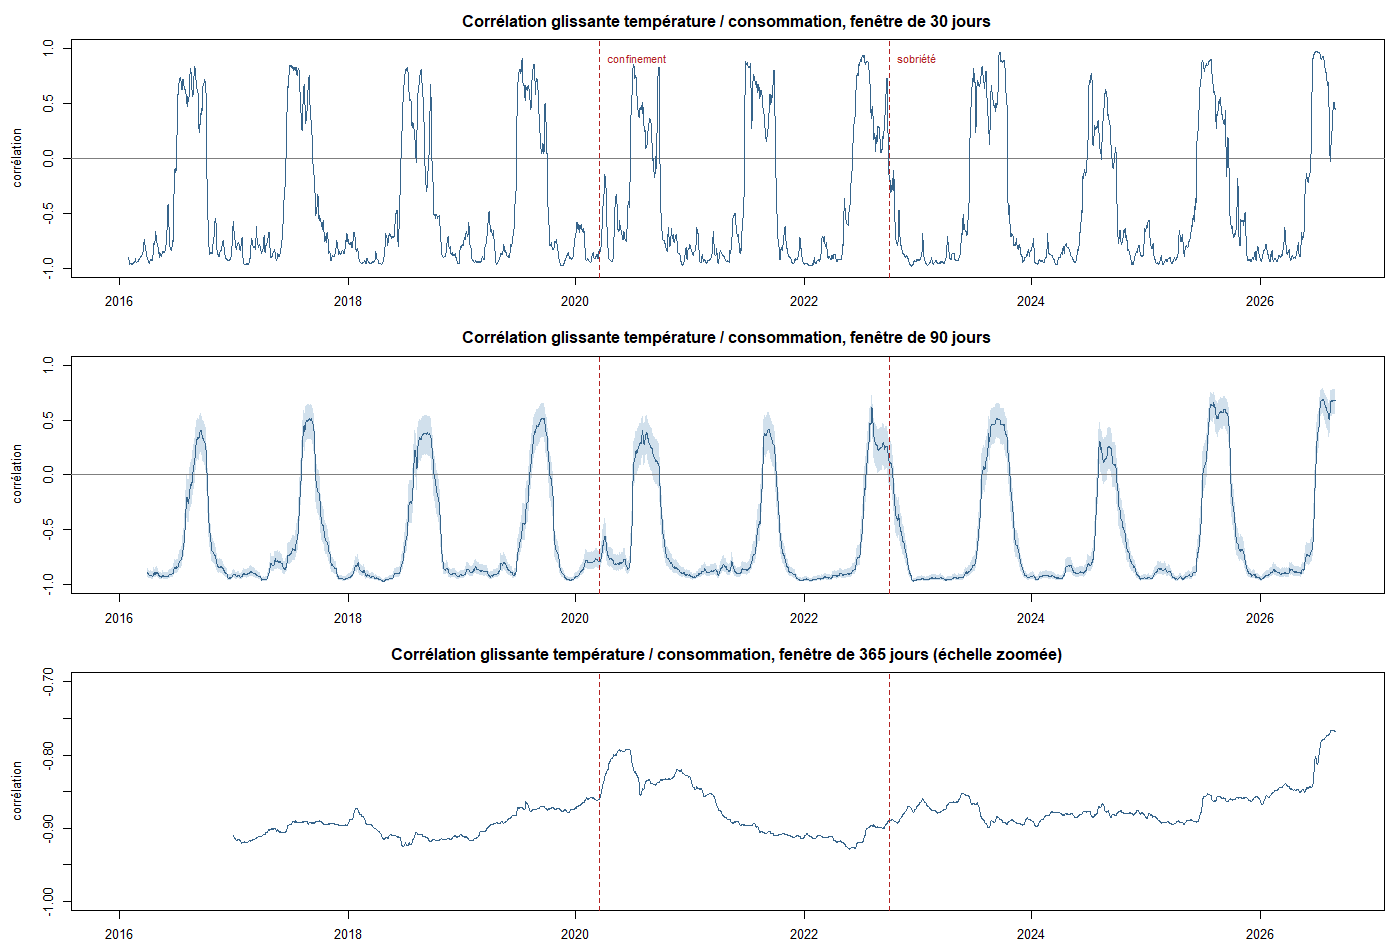

In [25]:
# corrélations glissantes sur 30, 90 et 365 jours
# Corrélation de Pearson sur une fenêtre qui avance d'un jour ; date = dernier jour de la fenêtre
roll_cor <- function(x, y, w) rollapply(cbind(x, y), w, function(m) cor(m[, 1], m[, 2]),
                                        by.column = FALSE, align = "right", fill = NA)
fenetres <- c(30, 90, 365)
for (w in fenetres) df[[paste0("rc", w)]] <- roll_cor(df$temp_moy, df$conso_adj, w)

# Intervalle à 95 % par la transformation de Fisher : z = atanh(r), écart-type 1/sqrt(w - 3)
# (approximatif : les jours consécutifs ne sont pas indépendants, la vraie bande est plus large)
fisher_ic <- function(r, w) cbind(tanh(atanh(r) - 1.96 / sqrt(w - 3)), tanh(atanh(r) + 1.96 / sqrt(w - 3)))
ic90 <- fisher_ic(df$rc90, 90)

resume_rc <- t(sapply(fenetres, function(w) {
  r <- df[[paste0("rc", w)]]
  c(fenetre = w, min = min(r, na.rm = TRUE), mediane = median(r, na.rm = TRUE), max = max(r, na.rm = TRUE),
    part_positive = mean(r > 0, na.rm = TRUE))
}))
print(round(resume_rc, 3))
write.csv(df[, c("date", paste0("rc", fenetres))], "exports/R/correlation_glissante_R.csv", row.names = FALSE)

png("figures/R/correlation_glissante_R.png", width = 1400, height = 950, res = 120)
par(mfrow = c(3, 1), mar = c(2.5, 4.5, 2.5, 1))
evts <- as.Date(c("2020-03-17", "2022-10-01"))                     # confinement, plan de sobriété
for (w in fenetres) {
  r <- df[[paste0("rc", w)]]
  # échelle resserrée pour 365 jours, sinon les variations sont invisibles
  plot(df$date, r, type = "n", ylim = if (w == 365) c(-1, -0.7) else c(-1, 1), xlab = "", ylab = "corrélation",
       main = sprintf("Corrélation glissante température / consommation, fenêtre de %d jours%s", w,
                      if (w == 365) " (échelle zoomée)" else ""))
  if (w == 90) polygon(c(df$date, rev(df$date))[!is.na(c(ic90[, 1], rev(ic90[, 2])))],
                       c(ic90[, 1], rev(ic90[, 2]))[!is.na(c(ic90[, 1], rev(ic90[, 2])))],
                       col = adjustcolor("steelblue", 0.25), border = NA)
  abline(h = 0, col = "grey50"); abline(v = evts, lty = 2, col = "firebrick")
  lines(df$date, r, col = "steelblue4", lwd = 1.2)
  if (w == 30) text(evts, 0.9, c("confinement", "sobriété"), pos = 4, col = "firebrick", cex = 0.85)
}
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/correlation_glissante_R.png")

### Lecture
- **Le lien n'est pas stable, il dépend de la saison.** Sur 90 jours, la corrélation reste autour de −0,9 d'octobre à juin : il fait froid, on chauffe. Elle devient **positive chaque fin d'été** (jusqu'à +0,69) : il fait chaud, on climatise. On retrouve la courbe en U de l'EDA, mais vue dans le temps.
- **Sur 30 jours**, ces bascules sont plus brutales (de −0,98 à +0,97). La fenêtre est courte et sensible à une seule vague de chaleur ou de froid.
- **Sur 365 jours**, le lien reste fort (entre −0,93 et −0,77), avec deux affaiblissements visibles :
  - **2020** : le confinement fait baisser la consommation de printemps sans lien avec la météo, ce qui casse temporairement la relation ;
  - **2026** : l'été 2026 est de loin le plus chaud de la série (260 degrés-jours de climatisation, contre 137 au précédent record de 2022). La climatisation ajoute de la consommation par temps chaud, ce qui affaiblit la corrélation linéaire négative.

## 24. Profil saisonnier et contrôle sur les variations journalières
Piège classique : en automne, la température baisse et la consommation monte, en partie par simple coïncidence de calendrier (les deux suivent les saisons). Pour contrôler, on recalcule la corrélation sur les **variations d'un jour à l'autre** : seule reste la réaction de la consommation à un changement de météo.

 mois niveaux variations
  Jan   -0.92      -0.68
  Feb   -0.88      -0.77
  Mar   -0.91      -0.80
  Apr   -0.91      -0.81
  May   -0.89      -0.69
  Jun   -0.85      -0.49
  Jul   -0.41      -0.09
  Aug    0.31       0.26
  Sep    0.34       0.36
  Oct   -0.40       0.19
  Nov   -0.83      -0.21
  Dec   -0.93      -0.57


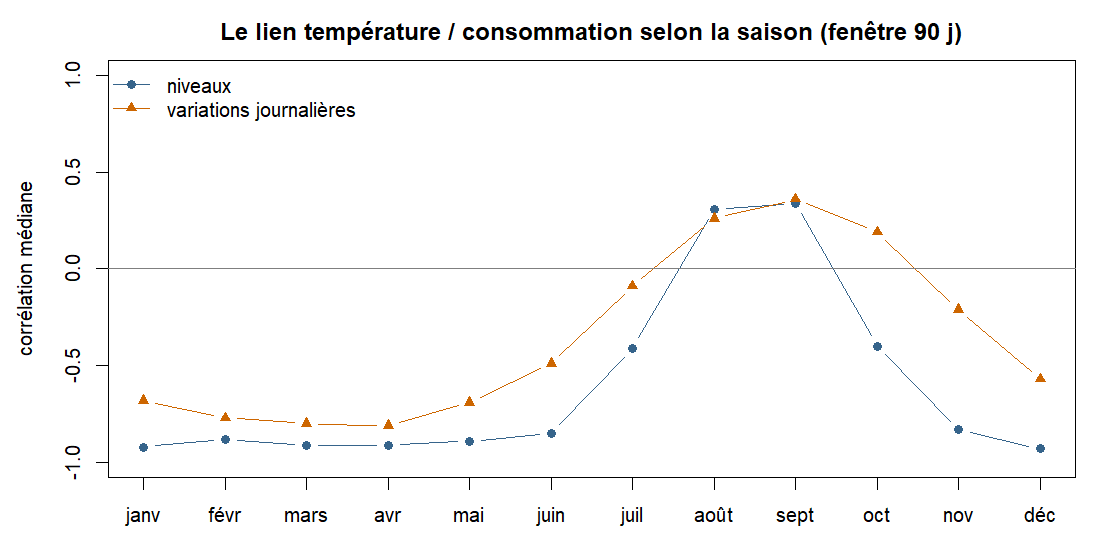

In [26]:
# profil saisonnier du lien (fenêtre de 90 jours) et contrôle sur les variations
# Médiane par mois de la corrélation à 90 jours (mois = dernier mois de la fenêtre)
mois <- as.integer(format(df$date, "%m"))
# Contrôle : en niveau, deux séries saisonnières se suivent en partie par simple coïncidence de calendrier.
# Sur les variations d'un jour à l'autre, seule la réaction de la consommation à un changement de météo reste.
df$rc90_diff <- roll_cor(c(NA, diff(df$temp_moy)), c(NA, diff(df$conso_adj)), 90)
df$rc90_diff[1:91] <- NA
profil <- data.frame(mois = month.abb,
                     niveaux = round(tapply(df$rc90, mois, median, na.rm = TRUE), 2),
                     variations = round(tapply(df$rc90_diff, mois, median, na.rm = TRUE), 2))
print(profil, row.names = FALSE)
write.csv(profil, "exports/R/correlation_profil_mensuel_R.csv", row.names = FALSE)

png("figures/R/correlation_profil_R.png", width = 1100, height = 550, res = 120)
par(mar = c(3, 4.5, 2.5, 1))
plot(1:12, profil$niveaux, type = "b", pch = 19, col = "steelblue4", ylim = c(-1, 1), xaxt = "n",
     xlab = "", ylab = "corrélation médiane", main = "Le lien température / consommation selon la saison (fenêtre 90 j)")
lines(1:12, profil$variations, type = "b", pch = 17, col = "darkorange3")
axis(1, 1:12, c("janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"))
abline(h = 0, col = "grey50")
legend("topleft", c("niveaux", "variations journalières"), col = c("steelblue4", "darkorange3"),
       pch = c(19, 17), lty = 1, bty = "n")
invisible(dev.off())
IRdisplay::display_png(file = "figures/R/correlation_profil_R.png")

### Lecture
Les deux courbes ont la même forme : le lien saisonnier n'est **pas une coïncidence de calendrier**. Même d'un jour à l'autre, un jour plus froid fait monter la consommation de décembre à mai (r ≈ −0,7 à −0,8), et un jour plus chaud la fait monter en août-septembre (r ≈ +0,3).
Le contrôle corrige l'automne : en octobre-novembre, la corrélation en niveaux (−0,4 et −0,83) était gonflée par la tendance commune. Sur les variations, elle est faible (+0,19 et −0,21), car le chauffage n'a pas encore vraiment démarré.

## 25. Évolution d'une année à l'autre et thermosensibilité de chaque hiver

In [27]:
# évolution d'une année à l'autre et thermosensibilité de chaque hiver
an <- as.integer(format(df$date, "%Y"))
par_an <- data.frame(annee = sort(unique(an)),
                     rc365_median = round(tapply(df$rc365, an, median, na.rm = TRUE), 3),
                     rc90_diff_median = round(tapply(df$rc90_diff, an, median, na.rm = TRUE), 2))
print(par_an, row.names = FALSE)
cat("Fenêtre de 365 jours où le lien est le plus faible : se terminant le",
    format(df$date[which.max(df$rc365)]), "(r =", round(max(df$rc365, na.rm = TRUE), 3), ")\n\n")

# Hiver = novembre à mars ; pente = GWh/jour supplémentaires par degré en moins
hiv <- mois %in% c(11, 12, 1, 2, 3)
saison <- ifelse(mois >= 11, an, an - 1)
hivers <- do.call(rbind, lapply(2016:2025, function(s) {
  d <- df[hiv & saison == s, ]
  if (nrow(d) < 120) return(NULL)                                   # hivers incomplets écartés
  m <- lm(conso_adj ~ temp_moy, data = d)
  data.frame(hiver = paste0(s, "-", s + 1), jours = nrow(d), correlation = round(cor(d$temp_moy, d$conso_adj), 3),
             pente_GWh_par_degre = round(coef(m)[[2]], 1),
             conso_a_8_degres = round(predict(m, data.frame(temp_moy = 8))))  # niveau à température égale
}))
print(hivers, row.names = FALSE)
write.csv(hivers, "exports/R/thermosensibilite_hivers_R.csv", row.names = FALSE)

 annee rc365_median rc90_diff_median
  2016       -0.911            -0.34
  2017       -0.896            -0.48
  2018       -0.911            -0.52
  2019       -0.879            -0.62
  2020       -0.833            -0.45
  2021       -0.896            -0.55
  2022       -0.910            -0.47
  2023       -0.877            -0.54
  2024       -0.880            -0.61
  2025       -0.864            -0.50
  2026       -0.845            -0.70
Fenêtre de 365 jours où le lien est le plus faible : se terminant le 2026-08-19 (r = -0.766 )

     hiver jours correlation pente_GWh_par_degre conso_a_8_degres
 2016-2017   151      -0.924               -50.8             1557
 2017-2018   151      -0.903               -44.9             1575
 2018-2019   151      -0.883               -47.8             1548
 2019-2020   152      -0.675               -40.2             1513
 2020-2021   151      -0.898               -46.3             1506
 2021-2022   151      -0.936               -56.5             1524

### Lecture
- La corrélation d'hiver est très stable (entre −0,88 et −0,95), sauf en **2019-2020** (−0,68), un hiver qui inclut le début du confinement de mars 2020.
- La **pente** (consommation supplémentaire par degré en moins) reste entre −45 et −57 GWh/jour, sans tendance : chaque degré de froid coûte toujours à peu près la même chose.
- En revanche, le **niveau à température égale** (consommation estimée à 8 °C) passe d'environ 1 550 GWh/jour avant 2020 à environ 1 450 depuis l'hiver 2022-2023.

## 26. La sobriété a-t-elle changé la sensibilité au froid ?
Régression sur les jours d'hiver, avec une rupture au 1er octobre 2022 : `post` mesure un **décalage de niveau**, `temp_moy:post` un **changement de pente**. Le premier confinement est exclu, et les erreurs standard sont de Newey-West (robustes à l'autocorrélation).

In [28]:
# la sobriété a-t-elle changé la sensibilité au froid ?
# Régression hivernale avec rupture au 1er octobre 2022 (plan de sobriété) :
# 'post' décale le niveau, 'temp_moy:post' modifie la pente ; le premier confinement est exclu
d <- df[hiv & saison %in% 2016:2025, ]
d$post <- as.numeric(d$date >= as.Date("2022-10-01"))
d <- d[!(d$date >= as.Date("2020-03-17") & d$date <= as.Date("2020-05-10")), ]
rupture <- lm(conso_adj ~ temp_moy * post, data = d)
# Erreurs standard de Newey-West : les jours d'hiver successifs sont autocorrélés,
# les erreurs standard classiques seraient trop optimistes
tab_rupture <- round(unclass(lmtest::coeftest(rupture, vcov. = sandwich::NeweyWest(rupture)))[, 1:4], 4)
colnames(tab_rupture) <- c("estimation", "ecart_type_NW", "t", "p_value")
print(tab_rupture)
write.csv(tab_rupture, "exports/R/rupture_sobriete_R.csv")
se_post <- tab_rupture["post", 2]
cat(sprintf("\nÀ température égale, la consommation d'hiver baisse de %.0f GWh/jour (IC 95 %% Newey-West : %.0f à %.0f) ;",
            -coef(rupture)[["post"]], -coef(rupture)[["post"]] - 1.96 * se_post, -coef(rupture)[["post"]] + 1.96 * se_post))
cat(sprintf("\nla pente passe de %.1f à %.1f GWh/jour par degré (différence p = %.2f).\n",
            coef(rupture)[["temp_moy"]], coef(rupture)[["temp_moy"]] + coef(rupture)[["temp_moy:post"]],
            tab_rupture["temp_moy:post", 4]))

              estimation ecart_type_NW        t p_value
(Intercept)    1929.5537       16.2234 118.9367  0.0000
temp_moy        -48.4193        1.6877 -28.6897  0.0000
post            -98.4199       22.7791  -4.3206  0.0000
temp_moy:post     0.7138        2.3006   0.3103  0.7564

À température égale, la consommation d'hiver baisse de 98 GWh/jour (IC 95 % Newey-West : 54 à 143) ;
la pente passe de -48.4 à -47.7 GWh/jour par degré (différence p = 0.76).


### Lecture : ce que la sobriété a changé
À température égale, la consommation d'hiver a **baissé d'environ 98 GWh/jour** (IC 95 % : 54 à 143) depuis octobre 2022. Mais la **sensibilité au froid n'a pas changé** : −48,4 avant, −47,7 GWh/jour par degré après (différence non significative, p = 0,76).

Interprétation : la sobriété a fait **baisser la consommation de base** (chauffage réglé plus bas, industrie qui produit moins, usages évités), sans modifier la façon dont la France réagit à une vague de froid. En pratique, la courbe consommation-température s'est **décalée vers le bas sans changer de pente**.

Ce résultat recoupe le **contrefactuel de sobriété** (section 7.2 du rapport), obtenu par une autre méthode, et peut servir de vérification croisée. Limite : la régression attribue à la sobriété toute baisse survenue après octobre 2022 ; d'autres facteurs de la même période (prix de l'énergie élevés, ralentissement industriel) ne sont pas séparés.